In [1]:
import os

# os.environ["HF_HOME"] = "/mnt/disks/ai-training/hf_cache"

import copy
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

from lecture_utils import (
    get_device, set_seed, load_stl10, STL10_CLASSES, Normalize, draw_joint_embedding_methods,
    knn_accuracy, rankme, embedding_std, singular_values, alignment, uniformity,
)
from vision_transformer import VisionTransformer

%matplotlib inline
warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", None)

In [2]:
DEVICE = get_device()
DATA_DIR = "../../data"
RESULTS_DIR = "results"      # small result tables of all training runs (part of the repo)
# The training runs of this lecture (58 runs, ResNet-18 on STL-10) take ~15 GPU-hours on an RTX 5090, so they are
# NOT started from the notebook. Launch them from a terminal in this folder:
#     python experiments.py --list              # what will be run
#     python experiments.py --gpus 0,1          # run everything (finished runs are skipped)
# The notebook only reads the logs they write to `results/`. All other cells run in a few seconds.

set_seed(95431)
print(f"torch {torch.__version__} | timm {timm.__version__} | device: {DEVICE}")

torch 2.11.0+cu130 | timm 1.0.30 | device: cuda


# Agenda

1. [Self-supervised learning with joint embeddings](#Intro)
2. [Data and evaluation protocol](#Data)
3. [Views: augmentations define what is learned](#Views)
4. [Contrastive learning: InfoNCE and SimCLR](#SimCLR)
5. [MoCo: negatives from a queue](#MoCo)
6. [Positives and negatives: a closer look](#Pos_Neg)
7. [Representation collapse](#Collapse)
8. [BYOL: learning without negatives](#BYOL)
9. [SimSiam: stop-gradient is all you need?](#SimSiam)
10. [Redundancy reduction: Barlow Twins and VICReg](#Redundancy)
11. [All methods under the same budget](#Comparison)
12. [What happened next (2022–2025)](#Recent)
13. [Practical guide](#Practice)
14. [Summary and self-check questions](#Summary)

# Resources

**The four methods of this lecture**
- [SimCLR: A Simple Framework for Contrastive Learning of Visual Representations (Chen et al., 2020)](https://arxiv.org/abs/2002.05709) and [SimCLR v2 (2020)](https://arxiv.org/abs/2006.10029)
- [MoCo: Momentum Contrast for Unsupervised Visual Representation Learning (He et al., 2019)](https://arxiv.org/abs/1911.05722), [MoCo v2 (2020)](https://arxiv.org/abs/2003.04297), [MoCo v3 (2021)](https://arxiv.org/abs/2104.02057)
- [BYOL: Bootstrap Your Own Latent (Grill et al., 2020)](https://arxiv.org/abs/2006.07733)
- [SimSiam: Exploring Simple Siamese Representation Learning (Chen & He, 2020)](https://arxiv.org/abs/2011.10566)

**Contrastive loss: where it comes from and what it does**
- [CPC / InfoNCE: Representation Learning with Contrastive Predictive Coding (van den Oord et al., 2018)](https://arxiv.org/abs/1807.03748)
- [Instance Discrimination (Wu et al., 2018)](https://arxiv.org/abs/1805.01978)
- [Understanding Contrastive Representation Learning through Alignment and Uniformity on the Hypersphere (Wang & Isola, 2020)](https://arxiv.org/abs/2005.10242)
- [Understanding the Behaviour of Contrastive Loss (temperature; Wang & Liu, 2020)](https://arxiv.org/abs/2012.09740)

**Views, positives and negatives**
- [What Makes for Good Views for Contrastive Learning? (Tian et al., 2020)](https://arxiv.org/abs/2005.10243)
- [SwAV (multi-crop; Caron et al., 2020)](https://arxiv.org/abs/2006.09882)
- [Intriguing Properties of Contrastive Losses (feature suppression; Chen et al., 2020)](https://arxiv.org/abs/2011.02803)
- [Debiased Contrastive Learning (Chuang et al., 2020)](https://arxiv.org/abs/2007.00224), [Contrastive Learning with Hard Negative Samples (Robinson et al., 2020)](https://arxiv.org/abs/2010.04592)
- [Supervised Contrastive Learning (Khosla et al., 2020)](https://arxiv.org/abs/2004.11362)
- [NNCLR: Nearest-Neighbor Contrastive Learning (Dwibedi et al., 2021)](https://arxiv.org/abs/2104.14548)
- [Decoupled Contrastive Learning (Yeh et al., 2021)](https://arxiv.org/abs/2110.06848)

**Collapse and non-contrastive learning**
- [BYOL works even without batch statistics (Richemond et al., 2020)](https://arxiv.org/abs/2010.10241)
- [DirectPred: Understanding Self-Supervised Learning Dynamics without Contrastive Pairs (Tian et al., 2021)](https://arxiv.org/abs/2102.06810)
- [Understanding Dimensional Collapse in Contrastive Self-supervised Learning (Jing et al., 2021)](https://arxiv.org/abs/2110.09348)
- [Barlow Twins (Zbontar et al., 2021)](https://arxiv.org/abs/2103.03230), [VICReg (Bardes et al., 2021)](https://arxiv.org/abs/2105.04906), [W-MSE: Whitening for Self-Supervised Representation Learning (Ermolov et al., 2020)](https://arxiv.org/abs/2007.06346)
- [Guillotine Regularization: why we remove the projector (Bordes et al., 2022)](https://arxiv.org/abs/2206.13378)
- [On the duality between contrastive and non-contrastive self-supervised learning (Garrido et al., 2022)](https://arxiv.org/abs/2206.02574)
- [RankMe (Garrido et al., 2022)](https://arxiv.org/abs/2210.02885) and [LiDAR (Thilak et al., 2023)](https://arxiv.org/abs/2312.04000)

**Surveys and recent work**
- [A Cookbook of Self-Supervised Learning (Balestriero et al., 2023)](https://arxiv.org/abs/2304.12210)
- [EMP-SSL: Towards Self-Supervised Learning in One Training Epoch (Tong et al., 2023)](https://arxiv.org/abs/2304.03977)
- [Occam's Razor for Self Supervised Learning (Ibrahim et al., 2024)](https://arxiv.org/abs/2406.10743)
- [You Don't Need Domain-Specific Data Augmentations When Scaling Self-Supervised Learning (Moutakanni et al., 2024)](https://arxiv.org/abs/2406.09294)
- [I-JEPA (Assran et al., 2023)](https://arxiv.org/abs/2301.08243) and [LeJEPA (Balestriero & LeCun, 2025)](https://arxiv.org/abs/2511.08544)
- [Scaling Language-Free Visual Representation Learning (Fan et al., 2025)](https://arxiv.org/abs/2504.01017)
- Code: [facebookresearch/moco](https://github.com/facebookresearch/moco), [facebookresearch/simsiam](https://github.com/facebookresearch/simsiam), [facebookresearch/vicreg](https://github.com/facebookresearch/vicreg), [google-research/simclr](https://github.com/google-research/simclr), [lightly](https://github.com/lightly-ai/lightly), [solo-learn](https://github.com/vturrisi/solo-learn)

<a id='Intro'></a>
# Self-supervised learning with joint embeddings

In Lecture 3 we **evaluated** encoders that somebody else had pre-trained: supervised ViTs, DINO, DINOv2/v3, MAE, CLIP. Most of them were trained **without a single label**, and several of them beat the supervised models on our downstream tasks. In this lecture and the next two we look at **how** such encoders are trained. Today: the family that started the modern wave, **joint-embedding** methods with two augmented views of an image — SimCLR, MoCo, BYOL, SimSiam, and their relatives.

## Why learn without labels

* Labels are the bottleneck, images are not. ImageNet-1k has 1.3M labeled images; DINOv2 was trained on 142M images and DINOv3 on 1.7B, none of them labeled.
* A label is a very **narrow** training signal: "this is a dog" says nothing about the pose, the background, the texture or the second object in the picture. A supervised encoder is free to throw all of that away.
* In many domains (medical, satellite, industrial inspection) labels need an expert, while raw images accumulate for free.

Self-supervised learning (SSL) replaces the label with a **pretext task** whose answer is computed from the data itself. Early pretext tasks were hand-designed puzzles: predict the rotation of an image, the relative position of two patches, the colour of a grayscale image. They worked, but the features were tied to the puzzle. Two ideas replaced them:

| Family | Pretext task | Examples | Where in this course |
|---|---|---|---|
| **Joint embedding** | two views of the same image must get **similar embeddings** | SimCLR, MoCo, BYOL, SimSiam, Barlow Twins, VICReg, SwAV, DINO | this lecture, Lecture 5 (self-distillation) |
| **Masked modeling** | reconstruct the **hidden part** of the input | BEiT, MAE, SimMIM | mentioned in Lecture 5 |
| **Image-text** | an image and its caption must get similar embeddings | CLIP, SigLIP | Lecture 6 |

## The joint-embedding recipe

Take an image $x$ and create two **views** $x_1 = t_1(x)$, $x_2 = t_2(x)$ with random augmentations $t_1, t_2 \sim \mathcal{T}$. Pass both through a network and ask the outputs to **agree**:

$$
x \;\xrightarrow{\;t \sim \mathcal{T}\;}\; x_i \;\xrightarrow{\;\text{backbone } f\;}\; h_i \;\xrightarrow{\;\text{projector } g\;}\; z_i, \qquad \text{make } z_1 \approx z_2 .
$$

* $h = f(x)$ is the **representation**: this is what we keep and evaluate (Lecture 3).
* $z = g(h)$ is the **embedding**: a small MLP head on top, used only by the loss and thrown away after training.

The network has to output the same thing for a cropped, recoloured, blurred version of an image. To do that it must recognise *what is in the image* and ignore *how the picture was taken*. The augmentations decide what counts as "the same" — they are the supervision signal.

## The one problem every method has to solve: collapse

"Make $z_1 \approx z_2$" has a trivial perfect solution: **output the same vector for every image**. The loss is zero and the representation is useless. This is **representation collapse**, and the whole zoo of methods is best understood as different answers to one question:

> **What stops the network from mapping everything to a constant?**

| Answer | Methods | Mechanism |
|---|---|---|
| **Contrastive** | SimCLR, MoCo | push the embeddings of *different* images (negatives) apart |
| **Asymmetric / distillation** | BYOL, SimSiam, DINO | no negatives; a predictor and a stop-gradient (and usually a momentum "teacher") break the symmetry between the two branches |
| **Redundancy reduction** | Barlow Twins, VICReg | no negatives and no asymmetry; constrain the statistics of the embedding dimensions over the batch |
| **Clustering** | SwAV, DeepCluster | views must be assigned to the same cluster, clusters must be used equally |

"Non-contrastive" in the title of the lecture means the second and third rows. The picture below shows the architectures we will implement.

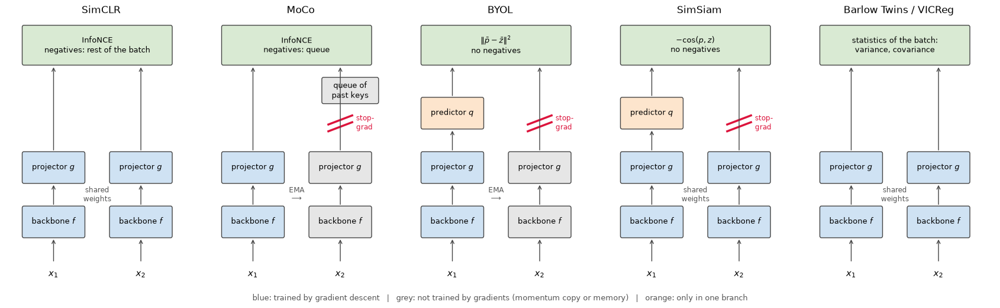

In [3]:
draw_joint_embedding_methods()
plt.show()

For reference, this is how the methods compare in the setting where they were published (ResNet-50, ImageNet-1k, linear probe on frozen features, long schedules). The numbers are from the original papers and are **not** fully comparable: the number of epochs, the batch size and the augmentations differ.

| Method | Year | Negatives | Momentum encoder | Predictor | ImageNet linear top-1 (ResNet-50) |
|---|---|---|---|---|---|
| Instance Discrimination | 2018 | memory bank | – | – | 54.0 |
| MoCo | 2019 | queue | yes | – | 60.6 |
| SimCLR | 2020 | batch | – | – | 69.3 |
| MoCo v2 | 2020 | queue | yes | – | 71.1 |
| SwAV (multi-crop) | 2020 | – (clusters) | – | – | 75.3 |
| BYOL | 2020 | – | yes | yes | 74.3 |
| SimSiam | 2020 | – | – | yes | 71.3 |
| Barlow Twins | 2021 | – | – | – | 73.2 |
| VICReg | 2021 | – | – | – | 73.2 |
| *Supervised* | | | | | *76.5* |

In two years the gap to supervised pre-training went from 20 points to almost nothing — and, as we saw in Lecture 3, on *transfer* tasks self-supervised encoders are often ahead.

<a id='Data'></a>
# Data and evaluation protocol

## STL-10

[STL-10](https://cs.stanford.edu/~acoates/stl10/) was built for exactly our purpose — unsupervised feature learning:

| Split | Images | Labels | We use it for |
|---|---|---|---|
| `unlabeled` | 100,000 | none | self-supervised pre-training |
| `train` | 5,000 (500 per class) | 10 classes | fitting the k-NN / linear probe |
| `test` | 8,000 (800 per class) | 10 classes | reporting accuracy |

The images come from ImageNet, downscaled to $96 \times 96$. The unlabeled part is drawn from a similar but broader distribution: besides the 10 classes it contains other animals and vehicles. This is the regime SSL was made for: **many unlabeled images, few labels**.

> The previous version of this lecture pre-trained on SnakeCLEF (fine-grained snake species). There, after 50 epochs, SimCLR and BYOL stayed below an ImageNet-pretrained ResNet-18 and close to a randomly initialized one in the linear probe, so the differences between methods could not be seen. STL-10 is small enough to train every method many times, which lets us run real ablations.

unlabeled: (100000, 3, 96, 96) | train: (5000, 3, 96, 96) | test: (8000, 3, 96, 96) | dtype: uint8


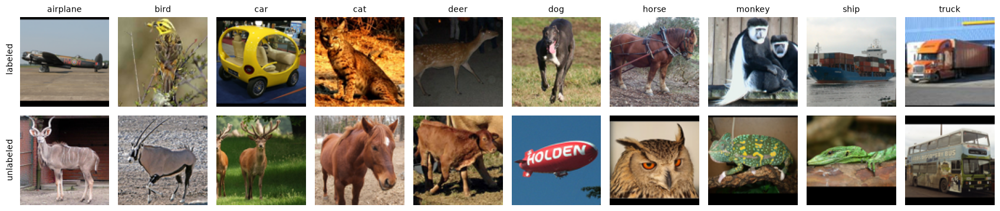

In [4]:
unlabeled_x, _ = load_stl10(DATA_DIR, "unlabeled")
train_x, train_y = load_stl10(DATA_DIR, "train")
test_x, test_y = load_stl10(DATA_DIR, "test")
print(f"unlabeled: {unlabeled_x.shape} | train: {train_x.shape} | test: {test_x.shape} | dtype: {unlabeled_x.dtype}")

fig, axes = plt.subplots(2, 10, figsize=(17, 3.8))
for c, ax_col in enumerate(axes.T):
    ax_col[0].imshow(train_x[np.flatnonzero(train_y == c)[0]].transpose(1, 2, 0))
    ax_col[0].set_title(STL10_CLASSES[c], fontsize=10)
    ax_col[1].imshow(unlabeled_x[c].transpose(1, 2, 0))
    ax_col[0].axis("off"); ax_col[1].axis("off")
fig.text(0.005, 0.72, "labeled", rotation=90, va="center"); fig.text(0.005, 0.27, "unlabeled", rotation=90, va="center")
plt.tight_layout(rect=(0.01, 0, 1, 1))
plt.show()

## How every run is trained and evaluated

All experiments of the lecture share one setup, so that the numbers are comparable:

| | |
|---|---|
| **Backbone** | ResNet-18 with a $3 \times 3$ stride-1 stem (the standard adaptation to small images), 11.2M parameters, output $h \in \mathbb{R}^{512}$. One run uses the ViT-Ti from Lecture 1. |
| **Data** | 100k unlabeled STL-10 images, two views per image |
| **Optimization** | SGD with momentum 0.9, 10 epochs of warmup and cosine decay, weight decay $5 \cdot 10^{-4}$, batch 512, mixed precision for the backbone. The learning rate is $\text{base} \cdot \text{batch} / 256$, with the base value chosen **per method** from a coarse grid in short pilot runs (0.24 for SimCLR, MoCo and BYOL, 0.12 for SimSiam and VICReg, 0.02 for Barlow Twins; SimSiam needed a second look, see its section) |
| **Budget** | 100 epochs for the main comparison, 30 epochs for every ablation |

Evaluation follows **Lecture 3**: the backbone is frozen, we compute $h$ for the 5k labeled training images and the 8k test images and report

* **k-NN accuracy** (weighted, $k = 20$, cosine similarity) — after every epoch, because it costs nothing;
* **linear probe accuracy** (L-BFGS logistic regression on standardized features, weight decay selected on a held-out part of the training split) — once, at the end.

In addition, every evaluation logs the **label-free diagnostics** that we will need to talk about collapse: the effective rank (RankMe) and the spread of the embeddings, both for $h$ and for $z$.

The code is in three files next to the notebook: `ssl_methods.py` (everything we implement below, as an importable module), `ssl_train.py` (the training loop) and `experiments.py` (the list of all runs). The cell below loads their results.

In [5]:
summary = pd.read_csv(os.path.join(RESULTS_DIR, "summary.csv")).set_index("name")


def load_run(name):
    """Per-epoch log of a run: loss, k-NN accuracy and diagnostics (NaN in epochs without evaluation)."""
    return pd.read_csv(os.path.join(RESULTS_DIR, "runs", f"{name}.csv"))


def load_steps(name):
    """Loss, learning rate and embedding std every few optimizer steps."""
    return pd.read_csv(os.path.join(RESULTS_DIR, "runs", f"{name}_steps.csv"))


def plot_runs(runs, metric, ax, title=None, ylabel=None, **kwargs):
    """runs: {run name: label}. Plots `metric` against the epoch."""
    for name, label in runs.items():
        d = load_run(name).dropna(subset=[metric])
        ax.plot(d["epoch"], d[metric], label=label, **kwargs)
    ax.set_xlabel("epoch"); ax.set_ylabel(ylabel or metric); ax.set_title(title or metric)
    ax.grid(alpha=0.3); ax.legend(fontsize=8)


def results_table(runs, columns=("knn_acc", "linear_acc", "rankme_h", "rankme_z", "std_z")):
    """runs: {run name: label}. Final metrics of the runs as a styled table."""
    table = summary.loc[list(runs), list(columns)].rename(index=runs)
    table.index.name = None
    fmt = {c: "{:.1%}" for c in columns if c.endswith("_acc") or c.endswith("acc_z")}
    fmt.update({c: "{:.0f}" for c in columns if c.startswith("rankme")})
    fmt.update({c: "{:.2f}" for c in columns if c in ("std_z", "std_h", "alignment", "uniformity", "final_loss")})
    return table.style.format(fmt).background_gradient(subset=[c for c in columns if "acc" in c], cmap="Greens")


RANDOM_INIT_KNN = load_run("simclr").iloc[0]["knn_acc"]     # epoch 0 of any ResNet-18 run = random init
print(f"{len(summary)} finished runs")
print(f"reference points: random-init ResNet-18, k-NN on frozen features: {RANDOM_INIT_KNN:.1%} | "
      f"supervised ResNet-18 on the 5k labeled images, k-NN: {summary.loc['supervised_5k', 'knn_acc']:.1%}")

58 finished runs
reference points: random-init ResNet-18, k-NN on frozen features: 29.5% | supervised ResNet-18 on the 5k labeled images, k-NN: 82.4%


Two reference points to keep in mind for the whole lecture:

* a **randomly initialized** ResNet-18 already gives non-trivial k-NN accuracy (chance is 10%): convolutions with random weights are a decent texture descriptor;
* the same ResNet-18 trained **with labels** on the 5,000 labeled images is what we could do without self-supervision.

The question for every method below is where it lands between and above these two.

<a id='Views'></a>
# Views: augmentations define what is learned

A joint-embedding method never sees a label. The only information it gets is: *"these two tensors come from the same image"*. So the augmentation distribution $\mathcal{T}$ plays the role that the label set plays in supervised learning:

> the network becomes **invariant** to everything the augmentations change, and must keep everything they preserve.

This cuts both ways. If the augmentations are too weak, the two views share **shortcuts** — cheap low-level cues that identify the image without understanding it. If they are too strong, they destroy the information we need downstream. Tian et al. (*What Makes for Good Views?*) call the sweet spot the **InfoMin** principle: good views share the task-relevant information **and as little else as possible**.

The pipeline that SimCLR found, and that almost every later method reuses:

| Augmentation | What it removes from "identity of the image" | Typical setting |
|---|---|---|
| **Random resized crop** (+ flip) | position, scale, framing; forces *part → whole* and *neighbour → neighbour* prediction | area 8–100% (we use 20–100%), aspect 3/4–4/3 |
| **Colour jitter** | exact colours and illumination | brightness, contrast, saturation 0.4, hue 0.1, applied with $p = 0.8$ |
| **Grayscale** | colour altogether, sometimes | $p = 0.2$ |
| **Gaussian blur** | fine texture and high frequencies | $p = 0.5$, $\sigma \in [0.1, 2]$ |
| Solarization (BYOL) | intensity statistics | $p = 0.2$ on one view only |

<img src="https://raw.githubusercontent.com/VSydorskyy/VSydorskyy/main/assets/kse_computer_vision/2026/Module_2/Lecture_4/images/simclr_views.png" width="380">

*Random crops create two kinds of prediction tasks: global → local (B → A) and adjacent views (D → C). Figure from the SimCLR paper.*

In `torchvision` the pipeline is five lines (`RandomResizedCrop`, `RandomHorizontalFlip`, `RandomApply([ColorJitter])`, `RandomGrayscale`, `RandomApply([GaussianBlur])`). On the CPU it costs ~4 ms per view for our $96 \times 96$ images, which would make data loading several times slower than the ResNet-18 itself. So we implement the same pipeline **for a whole batch on the GPU**: one affine resampling for crop + flip, colour operations as per-image arithmetic, and the blur as a grouped convolution with an individual kernel per image. The whole dataset (100k images, 2.8 GB as `uint8`) lives on the GPU, and there is no `DataLoader` at all.

In [6]:
class BatchAugment(nn.Module):
    """The SimCLR / MoCo v2 augmentation pipeline, applied to a whole batch on the GPU.

    Input: images (B, 3, H, W) with values in [0, 255]. Output: float images (B, 3, img_size, img_size) in [0, 1].
    Every image gets its own random parameters. Any step can be switched off (crop_scale=None, *_p=0).
    """

    def __init__(self, img_size=96, crop_scale=(0.2, 1.0), crop_ratio=(3 / 4, 4 / 3), flip_p=0.5,
                 jitter=(0.4, 0.4, 0.4, 0.1), jitter_p=0.8, gray_p=0.2, blur_p=0.5, blur_sigma=(0.1, 2.0),
                 solarize_p=0.0):
        super().__init__()
        self.img_size, self.crop_scale, self.crop_ratio, self.flip_p = img_size, crop_scale, crop_ratio, flip_p
        self.jitter, self.jitter_p, self.gray_p = jitter, jitter_p, gray_p
        self.blur_p, self.blur_sigma, self.solarize_p = blur_p, blur_sigma, solarize_p
        self.blur_kernel = 2 * int(0.05 * img_size) + 1                  # ~10% of the image size, odd
        self.register_buffer("gray_weights", torch.tensor([0.299, 0.587, 0.114]).view(1, 3, 1, 1))
        rgb_to_yiq = torch.tensor([[0.299, 0.587, 0.114], [0.5959, -0.2746, -0.3213], [0.2115, -0.5227, 0.3112]])
        self.register_buffer("rgb_to_yiq", rgb_to_yiq)
        self.register_buffer("yiq_to_rgb", torch.linalg.inv(rgb_to_yiq))

    @staticmethod
    def uniform(n, low, high, device):
        return torch.rand(n, device=device) * (high - low) + low

    @staticmethod
    def where(mask, a, b):
        return torch.where(mask.view(-1, 1, 1, 1), a, b)

    def gray(self, x):
        return (x * self.gray_weights).sum(dim=1, keepdim=True)

    def crop_and_flip(self, x):
        """Random resized crop + horizontal flip as one affine resampling."""
        b, dev = x.shape[0], x.device
        if self.crop_scale is None:
            w = h = torch.ones(b, device=dev)
        else:
            area = self.uniform(b, *self.crop_scale, dev)               # fraction of the image area
            ratio = self.uniform(b, math.log(self.crop_ratio[0]), math.log(self.crop_ratio[1]), dev).exp()
            w, h = (area * ratio).sqrt().clamp(max=1), (area / ratio).sqrt().clamp(max=1)   # fractions of W and H
        cx, cy = self.uniform(b, -1, 1, dev) * (1 - w), self.uniform(b, -1, 1, dev) * (1 - h)   # centre of the crop
        flip = torch.where(torch.rand(b, device=dev) < self.flip_p, -1.0, 1.0)
        theta = torch.zeros(b, 2, 3, device=dev)
        theta[:, 0, 0], theta[:, 0, 2], theta[:, 1, 1], theta[:, 1, 2] = w * flip, cx, h, cy
        grid = F.affine_grid(theta, (b, 3, self.img_size, self.img_size), align_corners=False)
        return F.grid_sample(x, grid, mode="bilinear", padding_mode="reflection", align_corners=False)

    def color_jitter(self, x):
        b, dev = x.shape[0], x.device
        brightness, contrast, saturation, hue = self.jitter
        for op in torch.randperm(4).tolist():                           # random order, as in torchvision
            if op == 0 and brightness > 0:
                x = x * self.uniform(b, 1 - brightness, 1 + brightness, dev).view(-1, 1, 1, 1)
            elif op == 1 and contrast > 0:
                mean = self.gray(x).mean(dim=(1, 2, 3), keepdim=True)
                x = (x - mean) * self.uniform(b, 1 - contrast, 1 + contrast, dev).view(-1, 1, 1, 1) + mean
            elif op == 2 and saturation > 0:
                g = self.gray(x)
                x = (x - g) * self.uniform(b, 1 - saturation, 1 + saturation, dev).view(-1, 1, 1, 1) + g
            elif op == 3 and hue > 0:                                   # rotate the chroma plane of YIQ
                angle = self.uniform(b, -hue, hue, dev) * 2 * math.pi
                rot = torch.zeros(b, 3, 3, device=dev)
                rot[:, 0, 0] = 1
                rot[:, 1, 1], rot[:, 1, 2], rot[:, 2, 1], rot[:, 2, 2] = angle.cos(), -angle.sin(), angle.sin(), angle.cos()
                x = torch.einsum("bij,bjhw->bihw", self.yiq_to_rgb @ rot @ self.rgb_to_yiq, x)
            x = x.clamp(0, 1)
        return x

    def gaussian_blur(self, x):
        """Separable Gaussian blur with an individual sigma per image (one grouped convolution per axis)."""
        b, c, h, w = x.shape
        k = self.blur_kernel
        sigma = self.uniform(b, *self.blur_sigma, x.device).view(-1, 1)
        offsets = torch.arange(k, device=x.device) - k // 2
        kernel = torch.exp(-offsets.pow(2) / (2 * sigma.pow(2)))        # (B, k)
        kernel = (kernel / kernel.sum(dim=1, keepdim=True)).repeat_interleave(c, dim=0)   # (B * C, k)
        x = F.pad(x.reshape(1, b * c, h, w), (k // 2, k // 2, k // 2, k // 2), mode="reflect")
        x = F.conv2d(x, kernel.view(b * c, 1, 1, k), groups=b * c)
        x = F.conv2d(x, kernel.view(b * c, 1, k, 1), groups=b * c)
        return x.reshape(b, c, h, w)

    @torch.no_grad()
    def forward(self, x):
        b, dev = x.shape[0], x.device
        x = x.float() / 255
        if self.crop_scale is not None or self.flip_p > 0 or x.shape[-1] != self.img_size:
            x = self.crop_and_flip(x)
        if self.jitter_p > 0:
            x = self.where(torch.rand(b, device=dev) < self.jitter_p, self.color_jitter(x), x)
        if self.gray_p > 0:
            x = self.where(torch.rand(b, device=dev) < self.gray_p, self.gray(x).expand(-1, 3, -1, -1), x)
        if self.blur_p > 0:
            x = self.where(torch.rand(b, device=dev) < self.blur_p, self.gaussian_blur(x), x)
        if self.solarize_p > 0:
            x = self.where(torch.rand(b, device=dev) < self.solarize_p, torch.where(x >= 0.5, 1 - x, x), x)
        return x.clamp(0, 1)

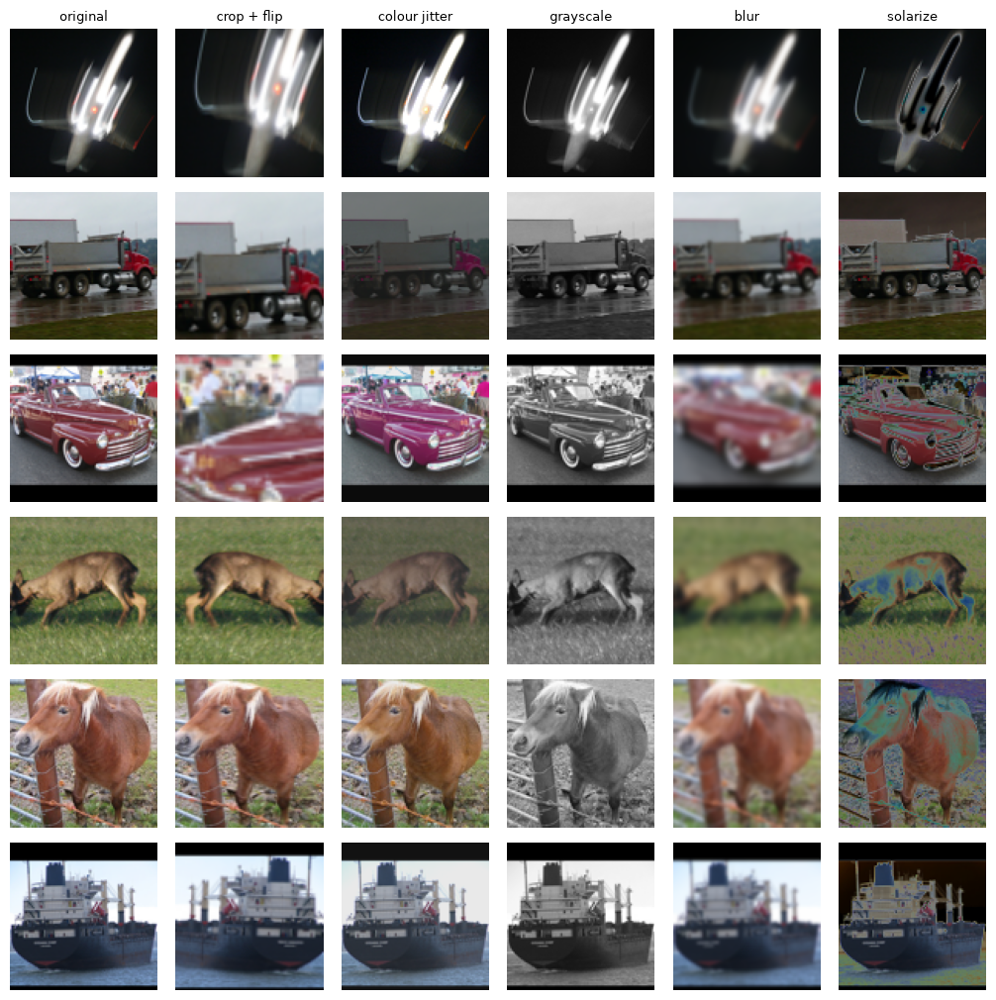

In [7]:
def show_images(images, titles=None, ncols=None, size=1.7, suptitle=None):
    """images: float tensor (N, 3, H, W) in [0, 1]."""
    ncols = ncols or len(images)
    nrows = math.ceil(len(images) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows + (0.4 if suptitle else 0)))
    for i, ax in enumerate(np.atleast_1d(axes).flatten()):
        ax.axis("off")
        if i < len(images):
            ax.imshow(images[i].permute(1, 2, 0).cpu().numpy())
            if titles is not None:
                ax.set_title(titles[i], fontsize=9)
    if suptitle:
        plt.suptitle(suptitle)
    plt.tight_layout()
    plt.show()


NO_AUG = dict(crop_scale=None, flip_p=0.0, jitter_p=0.0, gray_p=0.0, blur_p=0.0)
demo = torch.from_numpy(np.array(test_x[[4, 1300, 2500, 4100, 5700, 7300]])).to(DEVICE)   # six test images

set_seed(0)
single = {
    "original": {},
    "crop + flip": dict(crop_scale=(0.2, 1.0), flip_p=0.5),
    "colour jitter": dict(jitter_p=1.0),
    "grayscale": dict(gray_p=1.0),
    "blur": dict(blur_p=1.0),
    "solarize": dict(solarize_p=1.0),
}
rows = [BatchAugment(**{**NO_AUG, **kwargs}).to(DEVICE)(demo) for kwargs in single.values()]
show_images(torch.stack(rows, dim=1).flatten(0, 1), ncols=len(single),
            titles=list(single) + [""] * (len(single) * (len(demo) - 1)))

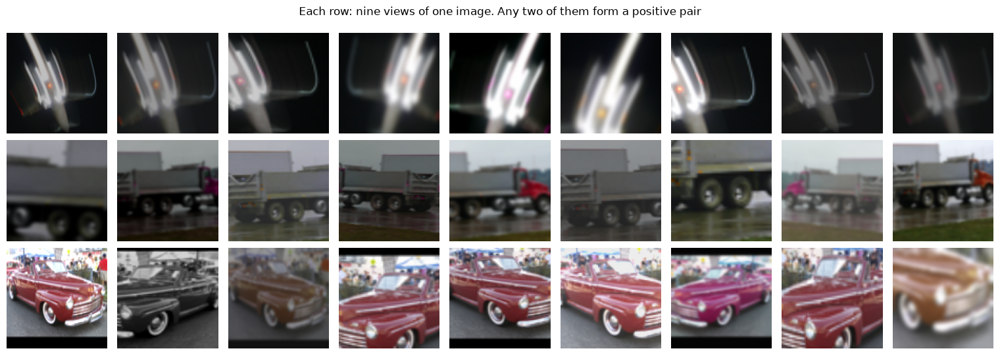

In [8]:
# What the network actually sees: several views of the same image with the full pipeline
set_seed(1)
augment = BatchAugment().to(DEVICE)
views = torch.stack([augment(demo[:3]) for _ in range(9)], dim=1)        # (3 images, 9 views, 3, 96, 96)
show_images(views.flatten(0, 1), ncols=9, suptitle="Each row: nine views of one image. Any two of them form a positive pair")

## Why colour distortion is essential: the histogram shortcut

The most cited ablation of the SimCLR paper: **no single augmentation is enough**, and the pair *random crop + colour distortion* stands out from all other pairs. The explanation is a shortcut. Two random crops of the same image have almost the same **colour histogram**, and histograms of different images differ. A network can therefore tell positives from negatives by looking at pixel statistics only — no shapes, no objects.

We can measure how strong this shortcut is without training anything. Take 2,000 test images, make two views of each, describe every view by nothing but its colour histogram ($3 \times 16$ numbers), and try to find, for each view, its partner among the 2,000 candidates.

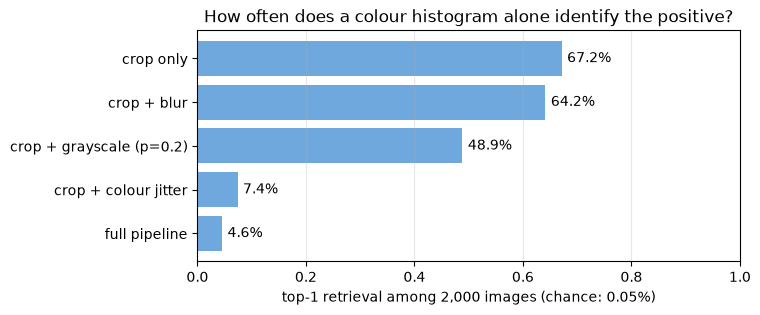

In [9]:
def color_histogram(x, bins=16):
    """x: (B, 3, H, W) in [0, 1] -> (B, 3 * bins) per-channel intensity histograms. No spatial information at all."""
    idx = (x.clamp(0, 1 - 1e-6) * bins).long().flatten(2)                                   # (B, 3, H * W)
    hist = torch.zeros(x.shape[0], 3, bins, device=x.device).scatter_add_(2, idx, torch.ones_like(idx, dtype=torch.float))
    return (hist / idx.shape[2]).flatten(1)


def retrieval_top1(a, b):
    """Fraction of rows of `a` whose most similar row of `b` is their own partner."""
    a, b = F.normalize(a, dim=1), F.normalize(b, dim=1)
    return ((a @ b.T).argmax(dim=1) == torch.arange(len(a), device=a.device)).float().mean().item()


images = torch.from_numpy(np.array(test_x[:2000])).to(DEVICE)
pipelines = {
    "crop only": dict(jitter_p=0.0, gray_p=0.0, blur_p=0.0),
    "crop + blur": dict(jitter_p=0.0, gray_p=0.0),
    "crop + grayscale (p=0.2)": dict(jitter_p=0.0, blur_p=0.0),
    "crop + colour jitter": dict(gray_p=0.0, blur_p=0.0),
    "full pipeline": {},
}
set_seed(0)
rows = []
for name, kwargs in pipelines.items():
    aug = BatchAugment(**kwargs).to(DEVICE)
    v1, v2 = aug(images), aug(images)
    rows.append({"views": name, "partner found by colour histogram": retrieval_top1(color_histogram(v1), color_histogram(v2))})
shortcut = pd.DataFrame(rows).set_index("views")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(shortcut.index[::-1], shortcut.iloc[::-1, 0], color="#6fa8dc")
for i, v in enumerate(shortcut.iloc[::-1, 0]):
    ax.text(v + 0.01, i, f"{v:.1%}", va="center")
ax.set_xlim(0, 1); ax.set_xlabel("top-1 retrieval among 2,000 images (chance: 0.05%)")
ax.set_title("How often does a colour histogram alone identify the positive?")
ax.grid(alpha=0.3, axis="x")
plt.show()

With crops only, **a 48-number colour histogram solves the pretext task for most images** — a network trained on such views has no reason to learn anything more. Blur does not touch the histogram, occasional grayscale removes the shortcut only for the images it hits. Colour jitter gives every view its own random colour transform and reduces the shortcut by an order of magnitude. That is why crop and colour distortion are useful only **together**: the crop creates the prediction task, the colour distortion closes the easy way out.

This is a general lesson of self-supervised learning: **the network will solve the pretext task in the cheapest possible way**, and method design is largely about removing cheap ways.

## Experiment: which augmentations does SimCLR need?

Now the real test. We train SimCLR (implemented in the next section) for 30 epochs with the full pipeline, and with parts of it removed. Later in the lecture we will come back to this figure and repeat two of the settings with BYOL.

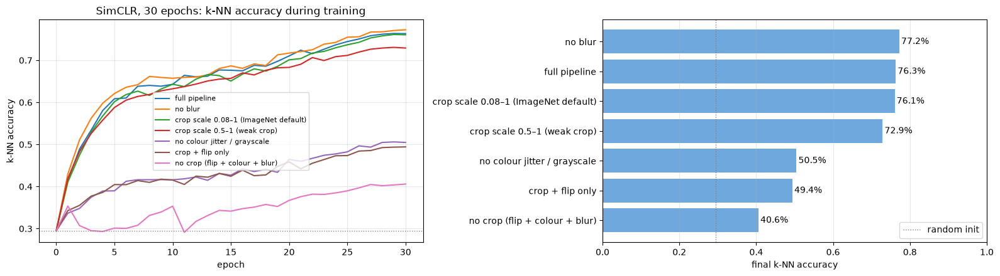

,knn_acc,linear_acc,rankme_h,final_loss
full pipeline,76.3%,80.1%,277,2.78
no blur,77.2%,80.1%,270,2.65
crop scale 0.08–1 (ImageNet default),76.1%,79.2%,265,3.10
crop scale 0.5–1 (weak crop),72.9%,75.9%,288,2.39
no colour jitter / grayscale,50.5%,57.2%,290,2.43
crop + flip only,49.4%,57.6%,284,2.37
no crop (flip + colour + blur),40.6%,45.8%,205,2.16


In [10]:
aug_runs = {
    "abl_simclr": "full pipeline",
    "aug_simclr_no_blur": "no blur",
    "aug_simclr_crop_008": "crop scale 0.08–1 (ImageNet default)",
    "aug_simclr_crop_05": "crop scale 0.5–1 (weak crop)",
    "aug_simclr_no_color": "no colour jitter / grayscale",
    "aug_simclr_crop_only": "crop + flip only",
    "aug_simclr_no_crop": "no crop (flip + colour + blur)",
}
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
plot_runs(aug_runs, "knn_acc", axes[0], title="SimCLR, 30 epochs: k-NN accuracy during training", ylabel="k-NN accuracy")
axes[0].axhline(RANDOM_INIT_KNN, color="gray", ls=":", lw=1)
final = summary.loc[list(aug_runs), "knn_acc"].rename(index=aug_runs).sort_values()
axes[1].barh(final.index, final.values, color="#6fa8dc")
for i, v in enumerate(final.values):
    axes[1].text(v + 0.005, i, f"{v:.1%}", va="center")
axes[1].axvline(RANDOM_INIT_KNN, color="gray", ls=":", lw=1, label="random init")
axes[1].set_xlim(0, 1); axes[1].set_xlabel("final k-NN accuracy"); axes[1].legend(); axes[1].grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()
results_table(aug_runs, columns=("knn_acc", "linear_acc", "rankme_h", "final_loss"))

### Takeaways (augmentations)

* **The crop is the task.** Without it SimCLR reaches 40.6% k-NN, only 11 points above a random network (29.5%): the two views are aligned pixel to pixel, and matching them needs no understanding of the content.
* **Colour distortion is the second requirement.** Removing it costs 26 points (76.3% → 50.5%), and "crop + flip only" gives 49.4% — exactly what the histogram shortcut predicts. These runs also have by far the worst alignment (≈1.5 against 0.2 for the full pipeline, measured on fully augmented pairs): the network never became invariant to colour, it used colour.
* **Blur does not matter here**: 77.2% without it against 76.3% with it. On $96 \times 96$ images it is the first thing to drop.
* **The crop has to be hard, but the exact range is not critical**: scale 0.08–1 and 0.2–1 give the same result (76.1% and 76.3%), a weak crop of 0.5–1 loses 3.4 points.
* Every setting is a single seed, so differences of about a point should be read as noise.

<a id='SimCLR'></a>
# Contrastive learning: InfoNCE and SimCLR

## From instance discrimination to InfoNCE

The first idea that worked at scale (Wu et al., 2018) sounds naive: treat **every image as its own class**. With $N$ images this is an $N$-way classification problem, and views of an image are the "training examples" of its class. A classifier with $N$ = millions of output weights is impractical, so the class weights are replaced by **embeddings of the other images**, and the softmax is computed over a *sample* of them.

That gives the loss used by every contrastive method. For an anchor embedding $z_i$, its positive $z_i^+$ (the other view of the same image) and a set of $K$ negatives $z_k^-$ (views of other images):

$$
\mathcal{L}_i = -\log \frac{\exp\big(\mathrm{sim}(z_i, z_i^+) / \tau\big)}{\exp\big(\mathrm{sim}(z_i, z_i^+) / \tau\big) + \sum_{k=1}^{K} \exp\big(\mathrm{sim}(z_i, z_k^-) / \tau\big)}, \qquad \mathrm{sim}(u, v) = \frac{u^\top v}{\lVert u \rVert \lVert v \rVert}.
$$

It is a plain **cross-entropy for a $(K + 1)$-way classification problem**: *"which of these $K + 1$ candidates is the other view of my image?"* The logits are cosine similarities divided by a **temperature** $\tau$.

The name **InfoNCE** comes from CPC (van den Oord et al., 2018), who showed that this loss is a lower bound on the mutual information between the two views:

$$
I(x_1; x_2) \;\ge\; \log(K + 1) - \mathcal{L}_{\text{InfoNCE}} .
$$

Two practical consequences: the bound **cannot exceed $\log(K + 1)$**, so with few negatives the task saturates quickly (one of the reasons contrastive methods like many negatives); and the loss value itself depends on $K$, so losses from runs with different batch or queue sizes are not comparable.

## NT-Xent: the SimCLR version

SimCLR takes negatives from the **same batch**. A batch of $N$ images gives $2N$ views. For each of the $2N$ views, its positive is the other view of the same image, and the remaining $2N - 2$ views are negatives. The loss is averaged over all $2N$ anchors (*NT-Xent*: normalized temperature-scaled cross-entropy).

<img src="https://raw.githubusercontent.com/VSydorskyy/VSydorskyy/main/assets/kse_computer_vision/2026/Module_2/Lecture_4/images/simclr_contrastive_learning.webp" width="480">

In code it is a similarity matrix and one call of `cross_entropy`:

In [11]:
def nt_xent(z1, z2, temperature=0.2):
    """NT-Xent (SimCLR): for each of the 2N views the positive is the other view of the same image,
    the negatives are the remaining 2N - 2 views in the batch."""
    n = z1.shape[0]
    z = F.normalize(torch.cat([z1, z2]), dim=1)                         # (2N, D), unit norm
    sim = z @ z.T / temperature                                         # (2N, 2N) cosine similarity / tau
    sim.fill_diagonal_(float("-inf"))                                   # a view is not its own negative
    targets = torch.cat([torch.arange(n, 2 * n), torch.arange(n)]).to(z.device)   # index of the positive
    return F.cross_entropy(sim, targets)


def nt_xent_loops(z1, z2, temperature=0.2):
    """The same loss written literally from the formula (slow, for checking)."""
    z = F.normalize(torch.cat([z1, z2]), dim=1)
    n, losses = len(z1), []
    for i in range(2 * n):
        pos = (i + n) % (2 * n)
        numerator = torch.exp(z[i] @ z[pos] / temperature)
        denominator = sum(torch.exp(z[i] @ z[k] / temperature) for k in range(2 * n) if k != i)
        losses.append(-torch.log(numerator / denominator))
    return torch.stack(losses).mean()


torch.manual_seed(0)
z1, z2 = torch.randn(8, 16), torch.randn(8, 16)
print(f"matrix version: {nt_xent(z1, z2).item():.6f} | loop version: {nt_xent_loops(z1, z2).item():.6f}")
print(f"random embeddings, N = 8: loss ~ log(2N - 1) = {math.log(15):.3f}")
print(f"positives identical, negatives orthogonal, tau = 0.2: {nt_xent(torch.eye(8), torch.eye(8)).item():.4f}")

matrix version: 2.798286 | loop version: 2.798286
random embeddings, N = 8: loss ~ log(2N - 1) = 2.708
positives identical, negatives orthogonal, tau = 0.2: 0.0901


## What the loss does to the embeddings: gradients

Write $s_{ik} = \mathrm{sim}(z_i, z_k)$ and let $p_{ik}$ be the softmax probability that anchor $i$ assigns to candidate $k$. Differentiating the cross-entropy:

$$
\frac{\partial \mathcal{L}_i}{\partial s_{i+}} = -\frac{1}{\tau}\,(1 - p_{i+}), \qquad
\frac{\partial \mathcal{L}_i}{\partial s_{ik}} = \frac{1}{\tau}\, p_{ik} \quad \text{for a negative } k .
$$

* The positive is **pulled** with a force proportional to how wrong the prediction still is.
* Every negative is **pushed** with a force proportional to $p_{ik} \propto \exp(s_{ik} / \tau)$. Negatives that are already far away get almost no gradient; negatives that look like the anchor get most of it. The contrastive loss does **hard-negative mining by itself** — this is why SimCLR needs no explicit mining.
* The total push equals the pull: $\sum_k p_{ik} = 1 - p_{i+}$. When the positive is recognised confidently, the gradient vanishes for that anchor.

The temperature controls **how concentrated** the push is. The cell below takes one anchor with 1,000 negatives and shows which of them receive the gradient.

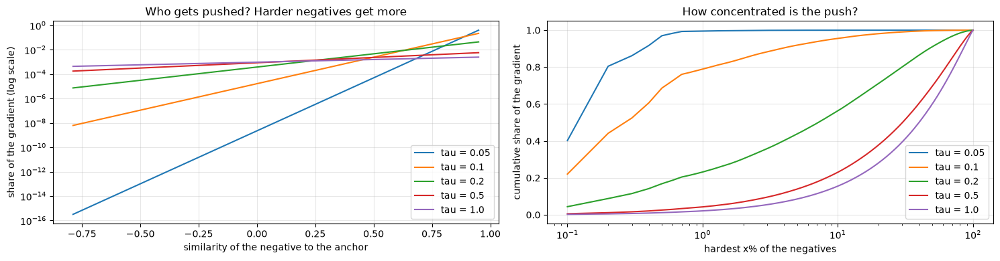

tau = 0.05: the 1% hardest negatives receive 99.5% of the gradient
tau = 0.1 : the 1% hardest negatives receive 78.9% of the gradient
tau = 0.2 : the 1% hardest negatives receive 23.2% of the gradient
tau = 0.5 : the 1% hardest negatives receive  4.3% of the gradient
tau = 1.0 : the 1% hardest negatives receive  2.1% of the gradient


In [12]:
torch.manual_seed(0)
neg_sims = (torch.randn(1000) * 0.25).clamp(-1, 0.95).sort().values      # cosine similarities of 1000 negatives
taus = [0.05, 0.1, 0.2, 0.5, 1.0]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
for tau in taus:
    weights = torch.softmax(neg_sims / tau, dim=0)                        # share of the "push" each negative receives
    axes[0].plot(neg_sims, weights, label=f"tau = {tau}")
    axes[1].plot(np.arange(1, 1001) / 10, weights.flip(0).cumsum(0), label=f"tau = {tau}")
axes[0].set_yscale("log"); axes[0].set_xlabel("similarity of the negative to the anchor")
axes[0].set_ylabel("share of the gradient (log scale)"); axes[0].set_title("Who gets pushed? Harder negatives get more")
axes[1].set_xscale("log"); axes[1].set_xlabel("hardest x% of the negatives"); axes[1].set_ylabel("cumulative share of the gradient")
axes[1].set_title("How concentrated is the push?")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()

for tau in taus:
    weights = torch.softmax(neg_sims / tau, dim=0)
    print(f"tau = {tau:<4}: the 1% hardest negatives receive {weights[-10:].sum().item():5.1%} of the gradient")

* **Small $\tau$**: almost all of the gradient goes to a handful of the most similar negatives. The model separates look-alike images very aggressively. But in an *unlabeled* batch the most similar negatives are often images **of the same class** — pushing them away is the opposite of what we want downstream.
* **Large $\tau$**: all negatives are pushed almost equally, the loss no longer cares about the hard ones and the embedding stays loosely organised.

Wang & Liu call this the **uniformity–tolerance dilemma**: a good temperature is low enough to spread the embeddings and high enough to tolerate semantically similar negatives. SimCLR uses $\tau = 0.1$–$0.5$ depending on the setup, MoCo v2 uses 0.2, CLIP learns it.

## Alignment and uniformity

Wang & Isola (2020) gave the cleanest description of what a contrastive loss optimizes. With embeddings on the unit sphere, and in the limit of many negatives, the loss splits into two terms:

$$
\mathcal{L}_{\text{InfoNCE}} \;\approx\; \underbrace{-\tfrac{1}{\tau}\,\mathbb{E}_{(x, x^+)}\big[z^\top z^+\big]}_{\textbf{alignment}:\ \text{positives close}}
\;+\; \underbrace{\mathbb{E}_{x}\Big[\log \mathbb{E}_{x^-} \exp\big(z^\top z^- / \tau\big)\Big]}_{\textbf{uniformity}:\ \text{all embeddings spread over the sphere}} + \text{const}.
$$

* **Alignment** alone is minimized by a constant output — collapse.
* **Uniformity** alone is minimized by random embeddings that ignore the image.
* Together they ask for the embedding that is **invariant to augmentations but otherwise preserves as much information as possible**.

Both can be measured on any encoder (we log them for all our runs):

$$
\ell_{\text{align}} = \mathbb{E}_{(x, x^+)} \lVert z - z^+ \rVert_2^2, \qquad
\ell_{\text{uniform}} = \log \mathbb{E}_{x, y}\, e^{-2 \lVert z_x - z_y \rVert_2^2} \qquad \text{(lower is better for both)}.
$$

A two-dimensional toy makes it visible. "Images" are points from six clusters in the plane, "augmentation" is Gaussian noise, the encoder is a small MLP whose output is normalized to the **unit circle**.

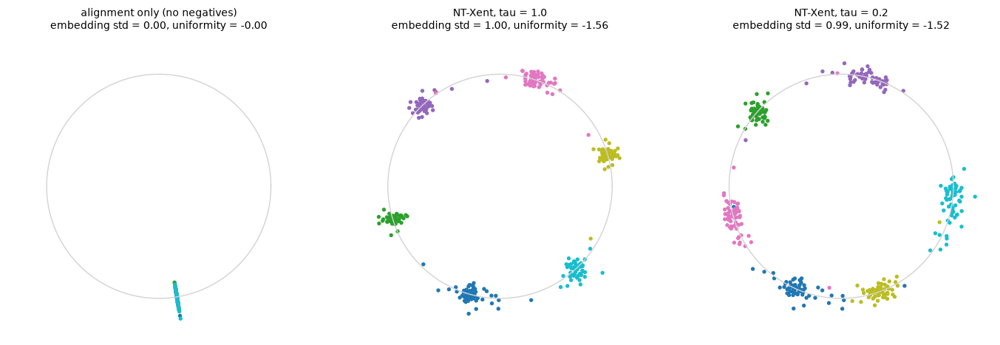

In [13]:
def toy_embedding(loss_name, tau=None, steps=1500, noise=0.6, seed=0):
    g = torch.Generator().manual_seed(seed)
    k, n = 6, 60
    angles = torch.arange(k) * 2 * math.pi / k
    points = (3 * torch.stack([angles.cos(), angles.sin()], dim=1)[:, None] + 0.5 * torch.randn(k, n, 2, generator=g)).reshape(-1, 2)
    labels = torch.arange(k).repeat_interleave(n)
    torch.manual_seed(seed)
    net = nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 2))
    opt = torch.optim.Adam(net.parameters(), lr=3e-3)
    for _ in range(steps):
        z1 = net(points + noise * torch.randn(points.shape))             # two "views" of every point
        z2 = net(points + noise * torch.randn(points.shape))
        if loss_name == "alignment":                                     # pull positives together, nothing else
            loss = (F.normalize(z1, dim=1) - F.normalize(z2, dim=1)).pow(2).sum(dim=1).mean()
        else:
            loss = nt_xent(z1, z2, tau)
        opt.zero_grad(); loss.backward(); opt.step()
    with torch.no_grad():
        return F.normalize(net(points), dim=1), labels


settings = [("alignment", None, "alignment only (no negatives)"), ("nt_xent", 1.0, "NT-Xent, tau = 1.0"), ("nt_xent", 0.2, "NT-Xent, tau = 0.2")]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.6))
circle = torch.linspace(0, 2 * math.pi, 200)
for ax, (loss_name, tau, title) in zip(axes, settings):
    z, labels = toy_embedding(loss_name, tau)
    radius = 1 + 0.05 * torch.randn(len(z), generator=torch.Generator().manual_seed(0))[:, None]      # jitter for visibility
    ax.plot(circle.cos(), circle.sin(), color="lightgray", lw=1)
    ax.scatter(*(z * radius).T, c=labels, cmap="tab10", s=8)
    ax.set_title(f"{title}\nembedding std = {embedding_std(z):.2f}, uniformity = {uniformity(z):.2f}", fontsize=10)
    ax.set_xlim(-1.35, 1.35); ax.set_ylim(-1.35, 1.35); ax.set_aspect("equal"); ax.axis("off")
plt.tight_layout()
plt.show()

With alignment only, all 360 points end up at **one point of the circle**: a perfect solution of "make the views agree" and a useless representation. Adding negatives spreads the points around the circle; nearby inputs still land close to each other, so the six clusters survive as six arcs. This picture — *collapse without a repulsive force* — is the core of the second half of the lecture, where the repulsive force will be replaced by something else.

## SimCLR

<img src="https://raw.githubusercontent.com/VSydorskyy/VSydorskyy/main/assets/kse_computer_vision/2026/Module_2/Lecture_4/images/simclr_scheme.png" width="360">

SimCLR is the simplest possible instance of the recipe: one network with shared weights for both views, NT-Xent on the outputs, negatives from the batch. Its contribution is the careful study of **what matters**:

1. **Composition of augmentations** — crop + colour distortion (previous section).
2. **A nonlinear projection head** $g$ between the representation $h$ and the loss. The representation *before* the head is much better than the one after it.
3. **Normalized embeddings and a temperature.**
4. **Large batches and long training** — more negatives per step, more steps.

The head is a 2-layer MLP; all heads in this lecture are built by one helper, `mlp`. All methods share one small interface, `SSLMethod`: `forward(x1, x2)` returns the loss for two batches of views, `backbone` and `projector` give $h$ and $z$, and `step_end` is a hook for momentum updates.

In [14]:
def mlp(dims, batch_norm=True, last_bn=False):
    """dims = [in, hidden, ..., out]: Linear -> (BN) -> ReLU for hidden layers, Linear -> (BN) for the last one."""
    layers = []
    for i in range(len(dims) - 2):
        layers.append(nn.Linear(dims[i], dims[i + 1], bias=not batch_norm))
        if batch_norm:
            layers.append(nn.BatchNorm1d(dims[i + 1]))
        layers.append(nn.ReLU(inplace=True))
    layers.append(nn.Linear(dims[-2], dims[-1], bias=not last_bn))
    if last_bn:
        layers.append(nn.BatchNorm1d(dims[-1]))
    return nn.Sequential(*layers)


class SSLMethod(nn.Module):
    """Common interface of all methods in this lecture."""

    def embed(self, x):
        h = self.backbone(x)
        return h, self.projector(h)

    def step_end(self, progress):
        pass


class SimCLR(SSLMethod):
    def __init__(self, backbone, feat_dim, proj_dim=128, hidden_dim=2048, temperature=0.2, projector="mlp",
                 loss="nt_xent"):
        super().__init__()
        self.backbone = backbone
        self.projector = {"mlp": lambda: mlp([feat_dim, hidden_dim, proj_dim]),
                          "linear": lambda: nn.Linear(feat_dim, proj_dim),
                          "none": lambda: nn.Identity()}[projector]()
        self.temperature = temperature
        self.loss = loss                       # "nt_xent", or "dcl" for the decoupled loss introduced later

    def forward(self, x1, x2):
        z1 = self.projector(self.backbone(x1))
        z2 = self.projector(self.backbone(x2))
        loss_fn = dcl_loss if self.loss == "dcl" else nt_xent
        return loss_fn(z1, z2, self.temperature)


backbone = timm.create_model("resnet18", pretrained=False, num_classes=0)       # any network that returns (B, feat_dim)
model = SimCLR(backbone, feat_dim=512)
x1, x2 = torch.randn(8, 3, 96, 96), torch.randn(8, 3, 96, 96)
print(model.projector)
print(f"loss at init: {model(x1, x2).item():.3f} (log(2N - 1) = {math.log(15):.3f})")

Sequential(
  (0): Linear(in_features=512, out_features=2048, bias=False)
  (1): BatchNorm1d(2048, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): Linear(in_features=2048, out_features=128, bias=True)
)
loss at init: 2.647 (log(2N - 1) = 2.708)


A full training step is exactly what you would expect — `loss = model(augment(x), augment(x))`, backward, optimizer step. See `ssl_train.py` for the complete loop (data on the GPU, mixed precision for the backbone, warmup + cosine schedule, evaluation every few epochs).

## Experiment: temperature

Five SimCLR runs that differ only in $\tau$. Besides accuracy we look at the alignment and uniformity of the learned embedding $z$, measured on a fixed set of 2,048 positive pairs from the test images.

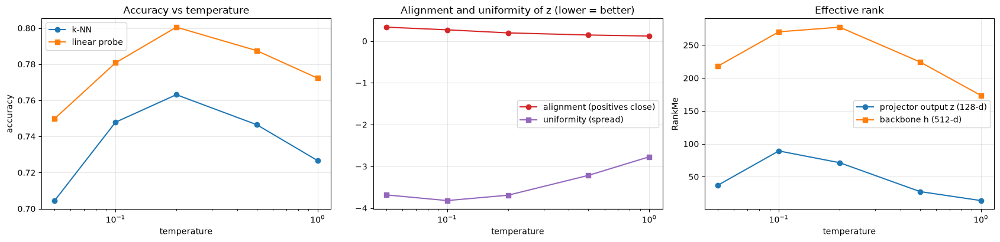

,knn_acc,linear_acc,alignment,uniformity,rankme_z
tau = 0.05,70.5%,75.0%,0.33,-3.68,37
tau = 0.1,74.8%,78.1%,0.27,-3.82,89
tau = 0.2,76.3%,80.1%,0.20,-3.69,71
tau = 0.5,74.7%,78.8%,0.14,-3.21,27
tau = 1.0,72.7%,77.2%,0.12,-2.77,14


In [15]:
temp_runs = {f"temp_simclr_{t}": t for t in [0.05, 0.1]} | {"abl_simclr": 0.2} | {f"temp_simclr_{t}": t for t in [0.5, 1.0]}
temp = summary.loc[list(temp_runs)].assign(tau=list(temp_runs.values()))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].plot(temp.tau, temp.knn_acc, "o-", label="k-NN"); axes[0].plot(temp.tau, temp.linear_acc, "s-", label="linear probe")
axes[0].set_xscale("log"); axes[0].set_xlabel("temperature"); axes[0].set_ylabel("accuracy"); axes[0].set_title("Accuracy vs temperature")
axes[1].plot(temp.tau, temp.alignment, "o-", color="tab:red", label="alignment (positives close)")
axes[1].plot(temp.tau, temp.uniformity, "s-", color="tab:purple", label="uniformity (spread)")
axes[1].set_xscale("log"); axes[1].set_xlabel("temperature"); axes[1].set_title("Alignment and uniformity of z (lower = better)")
axes[2].plot(temp.tau, temp.rankme_z, "o-", label="projector output z (128-d)"); axes[2].plot(temp.tau, temp.rankme_h, "s-", label="backbone h (512-d)")
axes[2].set_xscale("log"); axes[2].set_xlabel("temperature"); axes[2].set_ylabel("RankMe"); axes[2].set_title("Effective rank")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.show()
results_table({k: f"tau = {v}" for k, v in temp_runs.items()}, columns=("knn_acc", "linear_acc", "alignment", "uniformity", "rankme_z"))

### Takeaways (temperature)

* The best value is $\tau = 0.2$ (76.3% k-NN, 80.1% linear), and both ends lose: 70.5% k-NN at $\tau = 0.05$, 72.7% at $\tau = 1$. Temperature is the most important hyperparameter of a contrastive loss — a factor of 4 in either direction costs 4–6 points.
* **The trade-off predicted by the gradients is visible.** Alignment improves monotonically as $\tau$ grows (0.33 → 0.12): a soft loss does not fight over hard negatives, so positives can sit close together. Uniformity goes the other way: it is best at $\tau = 0.1$ (−3.82) and much worse at $\tau = 1$ (−2.77).
* **Even a contrastive embedding does not use its whole space.** The RankMe of $z$ is 37, 89, 71, 27 and 14 (out of 128) for the five temperatures. A high temperature leaves the embedding in a low-dimensional subspace; the backbone output follows (173 at $\tau = 1$ against 277 at $\tau = 0.2$).
* At low temperature $z$ is as good as $h$ for k-NN (71.3% vs 70.5% at $\tau = 0.05$); at $\tau = 1$ it is 4.5 points worse (68.2% vs 72.7%). The next experiment looks at this gap.

## Experiment: the projection head

The second finding of SimCLR is the strangest one. We train with (a) no head — the loss is applied to $h$ directly, (b) a linear head, (c) the MLP head. For each run we evaluate **both** spaces with k-NN: the backbone output $h$ (what we keep) and the head output $z$ (where the loss lives).

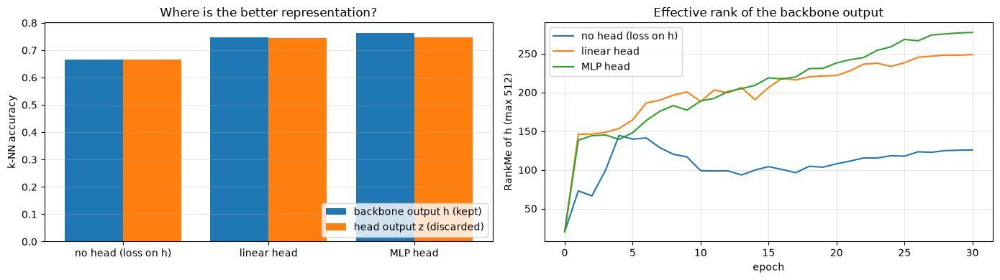

,knn_acc,knn_acc_z,linear_acc,rankme_h,rankme_z
no head (loss on h),66.7%,66.7%,69.9%,126,126
linear head,74.8%,74.3%,78.0%,249,68
MLP head,76.3%,74.6%,80.1%,277,71


In [16]:
proj_runs = {"proj_simclr_none": "no head (loss on h)", "proj_simclr_linear": "linear head", "abl_simclr": "MLP head"}
proj = summary.loc[list(proj_runs)]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
pos = np.arange(len(proj_runs))
axes[0].bar(pos - 0.2, proj.knn_acc, width=0.4, label="backbone output h (kept)")
axes[0].bar(pos + 0.2, proj.knn_acc_z, width=0.4, label="head output z (discarded)")
axes[0].set_xticks(pos, proj_runs.values()); axes[0].set_ylabel("k-NN accuracy"); axes[0].set_title("Where is the better representation?")
axes[0].grid(alpha=0.3, axis="y"); axes[0].legend(loc="lower right")
for name, label in proj_runs.items():
    d = load_run(name).dropna(subset=["rankme_h"])
    axes[1].plot(d.epoch, d.rankme_h, label=label)
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("RankMe of h (max 512)"); axes[1].set_title("Effective rank of the backbone output")
axes[1].grid(alpha=0.3); axes[1].legend()
plt.tight_layout()
plt.show()
results_table(proj_runs, columns=("knn_acc", "knn_acc_z", "linear_acc", "rankme_h", "rankme_z"))

Why would a layer that we throw away help? The accepted explanation:

* The loss demands **invariance** to the augmentations at its input. Information about colour, scale or orientation is *useless for the pretext task* and is removed from $z$ — but it may be very useful downstream (a flower classifier needs colour).
* With a head in between, the invariance is enforced on $z$, and $h$ — one nonlinear step earlier — is allowed to keep more. SimCLR showed that $h$ still linearly encodes the applied transformation much better than $z$.
* Bordes et al. call cutting the head **guillotine regularization** and show it is a general transfer-learning effect: the last layers specialise to the training objective, earlier layers generalise better.
* Jing et al. add a second view: without a head, the contrastive loss makes the embedding **dimensionally collapsed** (it occupies a low-dimensional subspace), and the head absorbs that collapse instead of the backbone. We will define this properly in the section on collapse.

### Takeaways (projection head)

* **A layer we throw away is worth 10 points of linear accuracy**: no head 69.9%, linear head 78.0%, MLP head 80.1% (k-NN: 66.7% / 74.8% / 76.3%).
* With a head, the backbone output is the better representation: 76.3% for $h$ against 74.6% for $z$ with the MLP head. With a linear head the gap is small (74.8% vs 74.3%) — a linear map cannot hide much.
* **The effective rank of $h$ shows why.** With the loss applied to $h$ directly, its RankMe is 126; with a linear head 249; with the MLP head 277. Without a head the dimensional collapse caused by the contrastive loss happens in the backbone; with a head, it happens in the head ($z$ has rank 71 of 128) and is cut off together with it.

## Experiment: batch size

In SimCLR the number of negatives is tied to the batch size: $2N - 2$. The paper reports steady gains up to a batch of 8192, which needs many GPUs (or TPUs) and the LARS optimizer. Here we go the other way and **shrink** the batch from 512 to 64, scaling the learning rate linearly with the batch size and keeping the number of *epochs* fixed, so small batches even get more optimizer steps.

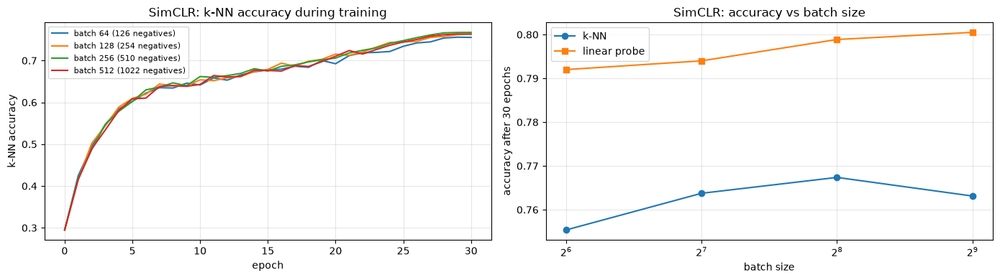

In [17]:
batch_runs = {"batch_simclr_64": 64, "batch_simclr_128": 128, "batch_simclr_256": 256, "abl_simclr": 512}
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_runs({k: f"batch {v} ({2 * v - 2} negatives)" for k, v in batch_runs.items()}, "knn_acc", axes[0],
          title="SimCLR: k-NN accuracy during training", ylabel="k-NN accuracy")
bs = summary.loc[list(batch_runs)]
axes[1].plot(list(batch_runs.values()), bs.knn_acc, "o-", label="k-NN"); axes[1].plot(list(batch_runs.values()), bs.linear_acc, "s-", label="linear probe")
axes[1].set_xscale("log", base=2); axes[1].set_xlabel("batch size"); axes[1].set_ylabel("accuracy after 30 epochs")
axes[1].set_title("SimCLR: accuracy vs batch size"); axes[1].grid(alpha=0.3); axes[1].legend()
plt.tight_layout()
plt.show()

### Takeaways (batch size)

* **At this scale SimCLR does not care about the batch size**: 75.5% / 76.4% / 76.7% / 76.3% k-NN for batches of 64 / 128 / 256 / 512, and 79.2%–80.1% linear. We do not reproduce the large-batch dependence of the paper, and it is worth understanding why:
    * STL-10 has about 10 classes, so 126 negatives already contain every other class many times; on ImageNet with 1000 classes a small batch misses most of them. More negatives here also means more *false* negatives (about one in ten).
    * We fix the number of epochs, so a batch of 64 makes 8× more optimizer steps. The SimCLR paper itself notes that the gap between batch sizes shrinks with longer training.
* What a small batch does cost is time: 13.8 minutes instead of 9.5 for the same number of images, because the GPU is used less efficiently.
* The claim "contrastive learning needs huge batches" is a statement about ImageNet-scale training with short schedules, not a law.

<a id='MoCo'></a>
# MoCo: negatives from a queue

SimCLR needs a huge batch because the batch is its only source of negatives. **MoCo** (He et al., 2019 — a few months *before* SimCLR) decouples the two.

## Contrastive learning as dictionary look-up

MoCo describes the task as a look-up in a dictionary: the anchor is a **query** $q$, the candidates are **keys** $k_0, k_1, \dots, k_K$, exactly one key $k_+$ matches the query. The loss is the same InfoNCE. The question is how to build a dictionary that is both **large** (many negatives) and **consistent** (all keys computed by roughly the same encoder):

| Dictionary | Size | Consistency | Problem |
|---|---|---|---|
| **End-to-end** (SimCLR): keys = the current batch | batch size | perfect | large dictionary = large batch = many GPUs |
| **Memory bank** (Instance Discrimination): one stored embedding per dataset image | whole dataset | poor: every key was computed by a different, old encoder | stale keys |
| **MoCo**: a **queue** of the keys from the last few batches, computed by a slowly moving **momentum encoder** | any (65,536 in the paper) | good | — |

Two ingredients:

1. **Queue.** After each step the keys of the current batch are enqueued and the oldest are dropped. Keys are just stored vectors without gradient, so 65k negatives cost only a matrix multiplication.
2. **Momentum encoder.** The keys cannot come from the query encoder: the queue would then mix outputs of very different networks (the encoder changes at every step). Instead the key encoder $\theta_k$ is an **exponential moving average** of the query encoder $\theta_q$, and receives no gradient:

$$
\theta_k \leftarrow m\,\theta_k + (1 - m)\,\theta_q, \qquad m = 0.999 .
$$

The MoCo paper shows how much the *slowness* matters (ImageNet linear accuracy, queue of 65,536): $m = 0$ (key encoder = query encoder) **fails to train**, $m = 0.9$ gives 55.2%, $m = 0.99$ 57.8%, $m = 0.999$ 59.0%. An EMA with momentum $m$ averages over roughly $1 / (1 - m)$ steps: 1000 steps for the paper's setting, 100 steps for our $m = 0.99$ (we train for only ~20k steps).

**MoCo v2** is MoCo plus the two tricks of SimCLR — the MLP head and the stronger augmentations (blur) — and reaches 71.1% with a batch of **256** on 8 GPUs, above SimCLR with a batch of 4096.

> **A multi-GPU detail.** With BatchNorm, the query and its positive key are in the same batch, and batch statistics can leak which samples belong together. MoCo shuffles the batch across GPUs for the key encoder ("shuffling BN"); SimCLR uses synchronized BN across devices. On a single GPU we do neither; keep it in mind if you port the code to several GPUs.

In [18]:
@torch.no_grad()
def ema_update(target, online, tau):
    """target <- tau * target + (1 - tau) * online, for all parameters."""
    for pt, po in zip(target.parameters(), online.parameters()):
        pt.mul_(tau).add_(po.detach(), alpha=1 - tau)


def frozen_copy(module):
    module = copy.deepcopy(module)
    for p in module.parameters():
        p.requires_grad = False
    return module


class MoCo(SSLMethod):
    """queue_size > 0: MoCo v2 (negatives come from a queue of past keys).
    queue_size = 0 and predictor=True: MoCo v3 (negatives are the other keys of the batch, extra predictor)."""

    def __init__(self, backbone, feat_dim, proj_dim=128, hidden_dim=2048, temperature=0.2, queue_size=16384,
                 momentum=0.99, predictor=False):
        super().__init__()
        self.backbone = backbone
        self.projector = mlp([feat_dim, hidden_dim, proj_dim])
        self.predictor = mlp([proj_dim, hidden_dim, proj_dim]) if predictor else nn.Identity()
        self.key_backbone, self.key_projector = frozen_copy(self.backbone), frozen_copy(self.projector)
        self.temperature, self.momentum = temperature, momentum
        if queue_size > 0:
            self.register_buffer("queue", F.normalize(torch.randn(queue_size, proj_dim), dim=1))
            self.register_buffer("queue_ptr", torch.zeros(1, dtype=torch.long))
        else:
            self.queue = None

    def contrast(self, q, k):
        if self.queue is None:                                          # in-batch negatives
            logits = q @ k.T                                            # (N, N), positives on the diagonal
            targets = torch.arange(len(q), device=q.device)
        else:                                                           # negatives from the queue
            l_pos = (q * k).sum(dim=1, keepdim=True)                    # (N, 1)
            l_neg = q @ self.queue.clone().detach().T                   # (N, K)
            logits = torch.cat([l_pos, l_neg], dim=1)                   # the positive is class 0
            targets = torch.zeros(len(q), dtype=torch.long, device=q.device)
        return F.cross_entropy(logits / self.temperature, targets)

    @torch.no_grad()
    def enqueue(self, keys):
        idx = (self.queue_ptr + torch.arange(len(keys), device=keys.device)) % len(self.queue)
        self.queue[idx] = keys                                          # overwrite the oldest keys (FIFO)
        self.queue_ptr[0] = (self.queue_ptr[0] + len(keys)) % len(self.queue)

    def forward(self, x1, x2):
        q1 = F.normalize(self.predictor(self.projector(self.backbone(x1))), dim=1)     # queries: gradient
        q2 = F.normalize(self.predictor(self.projector(self.backbone(x2))), dim=1)
        with torch.no_grad():                                                           # keys: no gradient
            k1 = F.normalize(self.key_projector(self.key_backbone(x1)), dim=1)
            k2 = F.normalize(self.key_projector(self.key_backbone(x2)), dim=1)
        loss = 0.5 * (self.contrast(q1, k2) + self.contrast(q2, k1))
        if self.queue is not None:
            self.enqueue(torch.cat([k1, k2]))
        return loss

    def step_end(self, progress):
        ema_update(self.key_backbone, self.backbone, self.momentum)
        ema_update(self.key_projector, self.projector, self.momentum)

In [19]:
# The queue is a ring buffer: with 8 slots and 3 images (6 keys) per step, the pointer wraps around
toy_backbone = nn.Sequential(nn.Flatten(), nn.Linear(3 * 8 * 8, 32))
moco = MoCo(toy_backbone, feat_dim=32, proj_dim=4, hidden_dim=16, queue_size=8)
for step in range(3):
    before = moco.queue.clone()
    loss = moco(torch.randn(3, 3, 8, 8), torch.randn(3, 3, 8, 8))
    moco.step_end(progress=0.0)                                           # momentum update of the key encoder
    changed = (moco.queue != before).any(dim=1).nonzero().flatten().tolist()
    print(f"step {step}: loss {loss.item():.3f} | overwritten slots {changed} | pointer -> {moco.queue_ptr.item()}")
print("trainable parameters:", sum(p.numel() for p in moco.parameters() if p.requires_grad),
      "| momentum (key) encoder parameters:", sum(p.numel() for p in moco.parameters() if not p.requires_grad))

step 0: loss 3.845 | overwritten slots [0, 1, 2, 3, 4, 5] | pointer -> 6
step 1: loss 3.276 | overwritten slots [0, 1, 2, 3, 6, 7] | pointer -> 4
step 2: loss 2.991 | overwritten slots [0, 1, 4, 5, 6, 7] | pointer -> 2
trainable parameters: 6788 | momentum (key) encoder parameters: 6788


Our implementation makes two choices that differ from the 2019 code and follow later practice:

* the loss is **symmetrized** (each view is used once as the query and once as the key), like in all other methods of this lecture;
* `queue_size=0, predictor=True` turns the same class into **MoCo v3**: the queue is dropped (with large batches it is not needed any more), the negatives are the other keys of the batch, and a BYOL-style predictor is added on the query side. MoCo v3 is the version made for Vision Transformers; we return to it at the end of the lecture.

## Experiment: how many negatives are enough?

With MoCo we can change the number of negatives without touching the batch. All runs below use a batch of 512 and differ only in the queue size $K$.

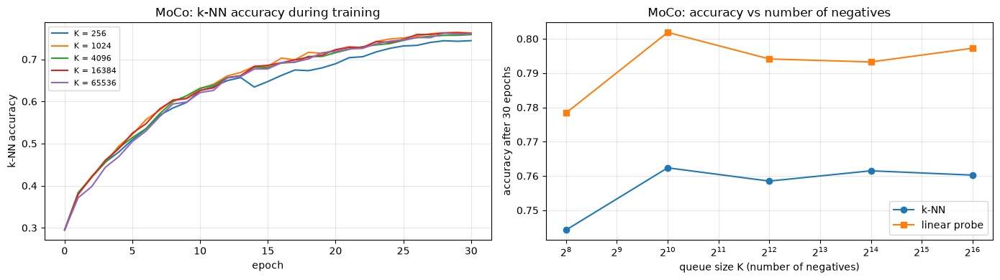

In [20]:
queue_runs = {f"queue_moco_{k}": k for k in [256, 1024, 4096]} | {"abl_moco": 16384, "queue_moco_65536": 65536}
qs = summary.loc[list(queue_runs)]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_runs({k: f"K = {v}" for k, v in queue_runs.items()}, "knn_acc", axes[0], title="MoCo: k-NN accuracy during training", ylabel="k-NN accuracy")
axes[1].plot(list(queue_runs.values()), qs.knn_acc, "o-", label="k-NN"); axes[1].plot(list(queue_runs.values()), qs.linear_acc, "s-", label="linear probe")
axes[1].set_xscale("log", base=2); axes[1].set_xlabel("queue size K (number of negatives)"); axes[1].set_ylabel("accuracy after 30 epochs")
axes[1].set_title("MoCo: accuracy vs number of negatives"); axes[1].grid(alpha=0.3); axes[1].legend()
plt.tight_layout()
plt.show()

### Takeaways (number of negatives)

* **About a thousand negatives are enough here.** $K = 256$ gives 74.4% k-NN / 77.8% linear; from $K = 1024$ on the curve is flat (76.2%, 75.9%, 76.2%, 76.0% k-NN up to $K = 65{,}536$).
* A queue that holds two thirds of the dataset neither helps nor hurts: stale keys are not a problem with momentum 0.99, but extra negatives of the same ten classes add nothing.
* MoCo with the default queue matches SimCLR with a batch of 512 (76.2% vs 76.3% k-NN, 79.3% vs 80.1% linear). The queue does not make the representation better — it makes the number of negatives **independent of the batch size**, which is what mattered on ImageNet with 8 GPUs.
* The price is a second forward pass through the momentum encoder: 12.8 minutes per run against 9.5 for SimCLR.

<a id='Pos_Neg'></a>
# Positives and negatives: a closer look

The contrastive loss rests on two assumptions that are both only approximately true:

* **a positive is a view of the same image** — but two views of one image are a very poor sample of "things that should be embedded together";
* **a negative is any other image** — but another image can show the same object.

A whole line of work improves one or the other.

## Negatives: false negatives, hard negatives and the coupling with the positive

**False negatives (class collision).** STL-10 has 10 balanced classes, so for any anchor about 10% of the "negatives" in a batch are images of the *same class*: ~100 out of 1,022 with our batch of 512. The loss pushes them away, and — as the gradient plot showed — it pushes hardest exactly on the most similar ones, which are the most likely to be false. On ImageNet with 1000 classes the rate is 0.1%, which is one reason contrastive learning looks better there than on datasets with few classes.

* *Debiased contrastive learning* (Chuang et al., 2020) corrects the denominator for the expected share of false negatives.
* *Hard negative sampling* (Robinson et al., 2020) up-weights negatives that are close to the anchor, on top of the debiasing — at a controlled rate instead of via a tiny temperature.
* *Supervised contrastive learning* (Khosla et al., 2020) shows the limit case: if labels are available, all same-class images are positives and none are negatives. SupCon beats cross-entropy training on ImageNet, which tells us that the *contrastive objective* is fine and the false negatives are a real cost.

**Negative–positive coupling.** Look at the gradient formulas again: every term is multiplied by $(1 - p_{i+})$, the probability mass *not* on the positive. With a small batch the positive is easily recognised among few easy negatives, $p_{i+} \to 1$, and the gradient vanishes — for the negatives too. *Decoupled contrastive learning* (DCL; Yeh et al., 2021) removes the positive from the denominator:

$$
\mathcal{L}_i^{\text{DCL}} = -\frac{s_{i+}}{\tau} + \log \sum_{k \ne i, +} \exp(s_{ik} / \tau).
$$

One changed line, and according to the paper much less sensitivity to the batch size (SimCLR at batch 256: +6.4 points on ImageNet after 200 epochs).

## Positives: beyond two views of one image

* **Multi-crop** (SwAV): two global crops plus several small low-resolution crops per image. Many more positive pairs per image for little compute; one of the biggest single improvements in SSL, and central to DINO (next lecture).
* **Nearest-neighbour positives** (NNCLR; Dwibedi et al., 2021): instead of pulling view 2 towards view 1, pull it towards the **nearest neighbour of view 1 in a memory of past embeddings**. The positive is now a *different image* that the model itself considers similar: more variation than any augmentation can create. The paper reports a gain of several points over SimCLR and much lower dependence on heavy augmentations.

In [21]:
def dcl_loss(z1, z2, temperature=0.2):
    """Decoupled contrastive loss (Yeh et al., 2021): NT-Xent with the positive removed from the denominator."""
    n = z1.shape[0]
    z = F.normalize(torch.cat([z1, z2]), dim=1)
    sim = z @ z.T / temperature
    targets = torch.cat([torch.arange(n, 2 * n), torch.arange(n)]).to(z.device)
    pos = sim.gather(1, targets[:, None]).squeeze(1)
    neg = sim.clone()
    neg.fill_diagonal_(float("-inf"))
    neg.scatter_(1, targets[:, None], float("-inf"))                    # drop the positive from the denominator
    return (-pos + torch.logsumexp(neg, dim=1)).mean()


class NNCLR(SSLMethod):
    """The positive of view 2 is not view 1 itself but its nearest neighbour in a support set of past embeddings."""

    def __init__(self, backbone, feat_dim, proj_dim=256, hidden_dim=2048, temperature=0.2, queue_size=16384):
        super().__init__()
        self.backbone = backbone
        self.projector = mlp([feat_dim, hidden_dim, hidden_dim, proj_dim], last_bn=True)
        self.predictor = mlp([proj_dim, hidden_dim, proj_dim])
        self.temperature = temperature
        self.register_buffer("queue", F.normalize(torch.randn(queue_size, proj_dim), dim=1))
        self.register_buffer("queue_ptr", torch.zeros(1, dtype=torch.long))

    @torch.no_grad()
    def nearest_neighbour(self, z):
        return self.queue[(z @ self.queue.T).argmax(dim=1)]

    @torch.no_grad()
    def enqueue(self, keys):
        idx = (self.queue_ptr + torch.arange(len(keys), device=keys.device)) % len(self.queue)
        self.queue[idx] = keys
        self.queue_ptr[0] = (self.queue_ptr[0] + len(keys)) % len(self.queue)

    def contrast(self, nn, p):
        logits = nn @ p.T / self.temperature                            # (N, N), positives on the diagonal
        return F.cross_entropy(logits, torch.arange(len(p), device=p.device))

    def forward(self, x1, x2):
        z1 = F.normalize(self.projector(self.backbone(x1)), dim=1)
        z2 = F.normalize(self.projector(self.backbone(x2)), dim=1)
        p1, p2 = F.normalize(self.predictor(z1), dim=1), F.normalize(self.predictor(z2), dim=1)
        nn1, nn2 = self.nearest_neighbour(z1.detach()), self.nearest_neighbour(z2.detach())
        loss = 0.5 * (self.contrast(nn1, p2) + self.contrast(nn2, p1))
        self.enqueue(z1.detach())
        return loss

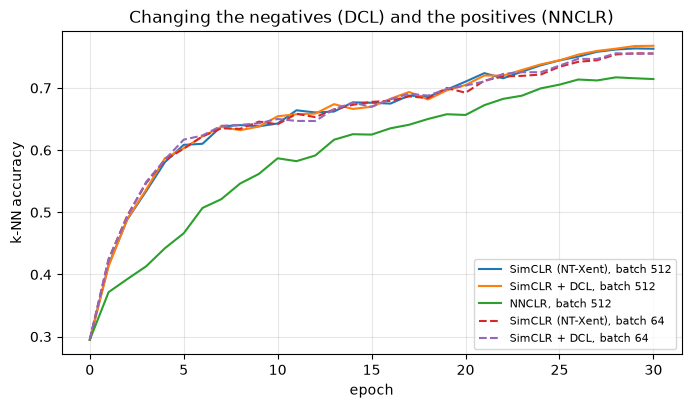

,knn_acc,linear_acc,alignment,uniformity
"SimCLR (NT-Xent), batch 512",76.3%,80.1%,0.20,-3.69
"SimCLR + DCL, batch 512",76.8%,79.7%,0.19,-3.69
"NNCLR, batch 512",71.4%,76.6%,0.14,-2.82
"SimCLR (NT-Xent), batch 64",75.5%,79.2%,0.19,-3.59
"SimCLR + DCL, batch 64",75.6%,78.9%,0.19,-3.60


In [22]:
loss_runs = {"abl_simclr": "SimCLR (NT-Xent), batch 512", "loss_simclr_dcl": "SimCLR + DCL, batch 512", "loss_nnclr": "NNCLR, batch 512",
             "batch_simclr_64": "SimCLR (NT-Xent), batch 64", "batch_simclr_dcl_64": "SimCLR + DCL, batch 64"}
fig, ax = plt.subplots(figsize=(8, 4.2))
for name, label in loss_runs.items():
    d = load_run(name).dropna(subset=["knn_acc"])
    ax.plot(d.epoch, d.knn_acc, label=label, ls="--" if "64" in label else "-")
ax.set_xlabel("epoch"); ax.set_ylabel("k-NN accuracy"); ax.set_title("Changing the negatives (DCL) and the positives (NNCLR)")
ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()
results_table(loss_runs, columns=("knn_acc", "linear_acc", "alignment", "uniformity"))

### Takeaways (positives and negatives)

* **DCL changes nothing in our setting**: 76.8% k-NN / 79.7% linear against 76.3% / 80.1% for NT-Xent at batch 512, and 75.6% / 78.9% against 75.5% / 79.2% at batch 64. This is consistent with the previous experiment: DCL repairs the small-batch weakness of NT-Xent, and at 10 classes with $\tau = 0.2$ we did not observe that weakness in the first place.
* **NNCLR is 5 points behind SimCLR after 30 epochs** (71.4% vs 76.3% k-NN, 76.6% vs 80.1% linear). Its positives come from the nearest neighbours in the model's own embedding, and early in training those neighbours are often of a different class. The paper trains for hundreds of epochs on ImageNet; a short budget is the worst case for this idea. Its embedding is also less uniform (−2.82 against −3.69).
* The general lesson: improvements reported at ImageNet scale are answers to ImageNet-scale problems. Check that you have the problem before adopting the fix.

<a id='Collapse'></a>
# Representation collapse

Negatives are expensive: they bring large batches or queues, a temperature, false negatives. Can we simply drop them? The toy example already gave the answer for the naive attempt — everything collapses. Before looking at methods that do work without negatives, let's define precisely what can go wrong and how to detect it **without labels**.

## Two kinds of collapse

Let $Z \in \mathbb{R}^{N \times D}$ be the embeddings of $N$ images.

* **Complete collapse**: all rows are (almost) the same vector. The representation carries no information.
* **Dimensional collapse**: the rows differ, but they lie in a **low-dimensional subspace** of $\mathbb{R}^D$. Some information survives, but a large part of the capacity is unused. This is the common, sneaky failure: the loss looks fine, the accuracy is just mediocre.

Diagnostics, all computed from $Z$ alone:

| Diagnostic | Definition | Healthy | Collapsed |
|---|---|---|---|
| **Embedding std** (SimSiam, Fig. 2) | std over the batch of each coordinate of $z / \lVert z \rVert$, averaged, times $\sqrt{D}$ | $\approx 1$ | $0$ |
| **Singular value spectrum** | singular values of the centred, normalized $Z$ (square roots of the eigenvalues of its covariance matrix) | flat or slowly decaying | all tiny (complete), or a few large and the rest tiny (dimensional) |
| **Effective rank, RankMe** (Lecture 3) | $\exp$ of the entropy of the normalized singular values | close to $D$ | 1 (complete) or $\ll D$ (dimensional) |

A synthetic illustration with $D = 64$:

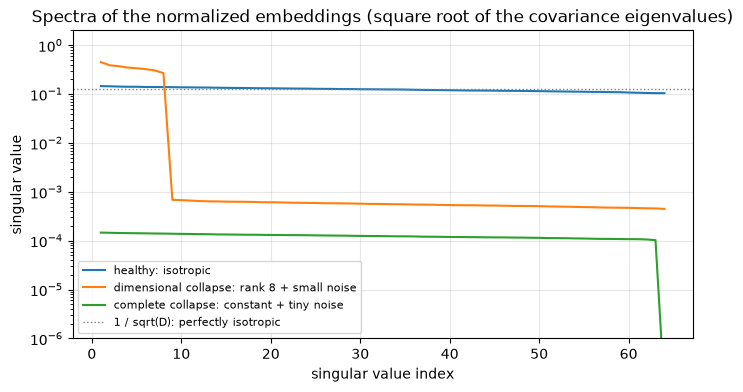

,embedding std,RankMe (max 64)
embeddings,,
healthy: isotropic,1.00,63.74
dimensional collapse: rank 8 + small noise,0.97,8.44
complete collapse: constant + tiny noise,0.00,1.08


In [23]:
torch.manual_seed(0)
n, d = 2000, 64
examples = {
    "healthy: isotropic": torch.randn(n, d),
    "dimensional collapse: rank 8 + small noise": torch.randn(n, 8) @ torch.randn(8, d) + 0.01 * torch.randn(n, d),
    "complete collapse: constant + tiny noise": torch.ones(n, d) + 1e-3 * torch.randn(n, d),
}
fig, ax = plt.subplots(figsize=(8, 4))
rows = []
for name, z in examples.items():
    ax.plot(np.arange(1, d + 1), singular_values(z), label=name)
    rows.append({"embeddings": name, "embedding std": embedding_std(z), "RankMe (max 64)": rankme(z)})
ax.axhline(1 / d ** 0.5, color="gray", ls=":", lw=1, label="1 / sqrt(D): perfectly isotropic")
ax.set_yscale("log"); ax.set_ylim(1e-6, 2); ax.set_xlabel("singular value index"); ax.set_ylabel("singular value")
ax.set_title("Spectra of the normalized embeddings (square root of the covariance eigenvalues)"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.show()
pd.DataFrame(rows).set_index("embeddings").round(2)

Note that the embedding std alone does **not** detect dimensional collapse — the second example has std close to 1 — which is why we log the effective rank as well. Jing et al. (2021) showed that even *contrastive* methods collapse dimensionally in the projector space; look again at the RankMe of $z$ in the temperature experiment above: far below its dimension of 128.

## Experiment: remove the negatives

To see collapse on real data we take the simplest non-contrastive objective: the same network for both views, **maximize the cosine similarity of the two embeddings**, nothing else. (In terms of the SimSiam class implemented below: no predictor and no stop-gradient.) For comparison: SimCLR, which has the same architecture plus negatives.

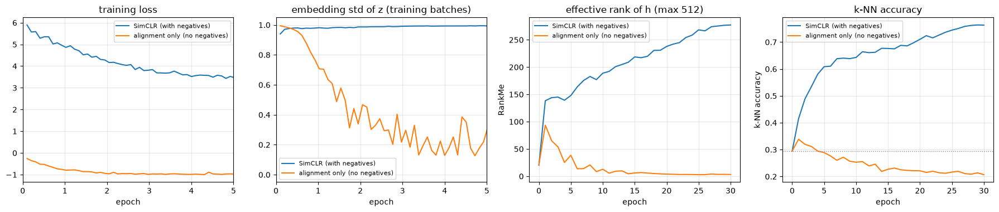

In [24]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.9))
col_runs = {"abl_simclr": "SimCLR (with negatives)", "col_simsiam_no_both": "alignment only (no negatives)"}
for name, label in col_runs.items():
    s = load_steps(name)
    axes[0].plot(s.epoch, s.loss, label=label)
    axes[1].plot(s.epoch, s.std_z, label=label)
axes[0].set_title("training loss"); axes[0].set_xlabel("epoch"); axes[0].set_xlim(0, 5)
axes[1].set_title("embedding std of z (training batches)"); axes[1].set_xlabel("epoch"); axes[1].set_xlim(0, 5)
plot_runs(col_runs, "rankme_h", axes[2], title="effective rank of h (max 512)", ylabel="RankMe")
plot_runs(col_runs, "knn_acc", axes[3], title="k-NN accuracy", ylabel="k-NN accuracy")
axes[3].axhline(RANDOM_INIT_KNN, color="gray", ls=":", lw=1)
for ax in axes[:2]:
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Takeaways (collapse)

* Without negatives the loss looks like a great success: it falls towards its minimum of −1 within the first few epochs (the learning rate is still warming up) and stays there.
* At the same time the embedding std of $z$ goes to 0 — all images get the same embedding.
* The backbone is damaged too: the effective rank of $h$ ends at 3 (of 512) and the k-NN accuracy at 20.7%, **below the 29.5% of the random network we started from**. Collapse does not just fail to learn, it destroys the features of the initialization.
* **The loss cannot tell you this.** Monitor the embedding std and the effective rank from the first step of any joint-embedding run.

<a id='BYOL'></a>
# BYOL: learning without negatives

In June 2020 **BYOL** (Bootstrap Your Own Latent) reported 74.3% on ImageNet — better than SimCLR and MoCo v2 — **with no negatives at all**. At the time this looked almost paradoxical: what prevents the collapse we have just seen?

<img src="https://raw.githubusercontent.com/VSydorskyy/VSydorskyy/main/assets/kse_computer_vision/2026/Module_2/Lecture_4/images/byol_scheme.png" width="800">

BYOL has two networks:

* the **online** network: backbone $f_\theta$, projector $g_\theta$ and an extra **predictor** $q_\theta$;
* the **target** network: backbone $f_\xi$ and projector $g_\xi$ with the same architecture, **not trained by gradients**: its weights are an exponential moving average of the online weights.

The online network sees view 1 and must **predict the target network's projection of view 2**:

$$
\mathcal{L}_{\theta, \xi} = \big\lVert\, \overline{q_\theta(z_\theta^{(1)})} - \overline{z_\xi^{(2)}} \,\big\rVert_2^2 = 2 - 2\cos\big(q_\theta(z_\theta^{(1)}),\, z_\xi^{(2)}\big), \qquad \bar{u} = u / \lVert u \rVert ,
$$

symmetrized by swapping the views. After every optimizer step

$$
\xi \leftarrow \tau\,\xi + (1 - \tau)\,\theta, \qquad \tau: 0.996 \to 1 \text{ with a cosine schedule}.
$$

There are three asymmetries between the branches: the **predictor** exists only online, the gradient flows **only through the online branch** (stop-gradient on the target), and the target weights are a **slow average**. Compare with MoCo: the momentum encoder is the same idea, but there it served the consistency of the queue; here there is no queue and no negatives.

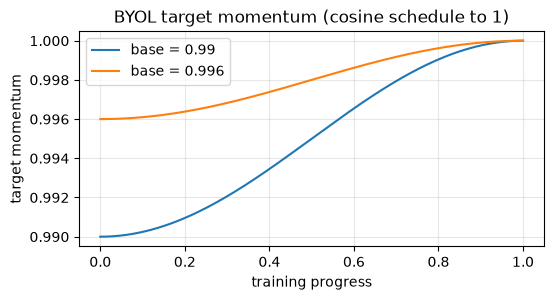

In [25]:
def byol_loss(p, z):
    """Squared distance between unit vectors = 2 - 2 cos(p, z). No gradient through the target z."""
    return (2 - 2 * F.cosine_similarity(p, z.detach(), dim=1)).mean()


class BYOL(SSLMethod):
    def __init__(self, backbone, feat_dim, proj_dim=256, hidden_dim=2048, ema=0.99, ema_schedule=True,
                 predictor=True, batch_norm=True):
        super().__init__()
        self.backbone = backbone                                         # online network: backbone + projector
        self.projector = mlp([feat_dim, hidden_dim, proj_dim], batch_norm=batch_norm)
        self.predictor = mlp([proj_dim, hidden_dim, proj_dim], batch_norm=batch_norm) if predictor else nn.Identity()
        self.target_backbone, self.target_projector = frozen_copy(self.backbone), frozen_copy(self.projector)
        self.ema, self.ema_schedule = ema, ema_schedule

    def forward(self, x1, x2):
        p1 = self.predictor(self.projector(self.backbone(x1)))
        p2 = self.predictor(self.projector(self.backbone(x2)))
        with torch.no_grad():
            t1 = self.target_projector(self.target_backbone(x1))
            t2 = self.target_projector(self.target_backbone(x2))
        return 0.5 * (byol_loss(p1, t2) + byol_loss(p2, t1))

    def step_end(self, progress):
        # cosine schedule of the momentum from `ema` to 1 (the target moves slower and slower)
        tau = 1 - (1 - self.ema) * (math.cos(math.pi * progress) + 1) / 2 if self.ema_schedule else self.ema
        ema_update(self.target_backbone, self.backbone, tau)
        ema_update(self.target_projector, self.projector, tau)


# The momentum schedule: the target follows the online network quickly at first and freezes at the end
progress = np.linspace(0, 1, 200)
plt.figure(figsize=(6, 2.8))
for base in [0.99, 0.996]:
    plt.plot(progress, 1 - (1 - base) * (np.cos(np.pi * progress) + 1) / 2, label=f"base = {base}")
plt.xlabel("training progress"); plt.ylabel("target momentum"); plt.grid(alpha=0.3); plt.legend()
plt.title("BYOL target momentum (cosine schedule to 1)")
plt.show()

## Why doesn't it collapse?

A constant output *is* still a global minimum of the BYOL loss. The point is that the training dynamics do not go there. Several pieces of evidence, in historical order:

**1. The target network gives a moving but informative target (BYOL paper).** The authors' starting observation: train the online network to predict the output of a **fixed, randomly initialized** target network. The result does not collapse (a random network gives different outputs for different images) and reaches 18.8% ImageNet linear accuracy, while the random network itself gives 1.4%. Predicting a fixed random target already *improves* the representation — so iterate: use the improved network as the new target ("bootstrap"). The EMA is the smooth version of this iteration.

**2. The updates are not gradient descent on any single loss.** $\theta$ follows $\nabla_\theta \mathcal{L}$, but $\xi$ does not follow $\nabla_\xi \mathcal{L}$ — it follows $\theta$. Like in GANs, there is no joint objective whose minimum the system must reach, so "the collapsed solution has the lowest loss" does not imply "training converges to it". The BYOL paper argues that, under the assumption of an optimal predictor, the collapsed solutions are *unstable* equilibria of these dynamics.

**3. "It is secretly contrastive through BatchNorm" — tested and rejected.** Soon after the paper, independent reproductions reported that BYOL collapses when BatchNorm is removed from its MLP heads, and the natural hypothesis was that BN — whose output depends on the other images of the batch — acts as an implicit contrastive term. Richemond et al. (2020) replaced BN by GroupNorm with weight standardization, which use **no batch statistics**, and obtained 73.9% vs 74.3%. Batch statistics help optimization, but they are not what prevents collapse.

**4. The predictor learns the statistics of the embedding (DirectPred; Tian et al., 2021).** In a linear model of BYOL / SimSiam one can solve the dynamics: with stop-gradient and a predictor, the eigenvectors of the predictor align with the eigenvectors of the embedding's correlation matrix, and weight decay removes the directions that carry no signal. Without stop-gradient or without the predictor, all directions shrink — collapse. The theory is good enough to **replace the trained predictor by a closed-form one** computed from the correlation matrix (DirectPred), which performs on par with a trained two-layer predictor and better than a trained linear one.

The practical summary: **predictor + stop-gradient are necessary; the EMA is not necessary but makes training more stable and better**. We now test each claim.

## Experiment: remove BYOL's ingredients

| Run | Change | The BYOL paper reports (ImageNet) |
|---|---|---|
| `BYOL` | – | 72.5% at 300 epochs |
| no predictor | online output compared with the target directly | collapse |
| $\tau = 0$ | target = online network at every step (still with stop-gradient). This is SimSiam with BYOL's heads | collapse (0.3%) in their setup |
| $\tau = 1$ | target = fixed random network | 18.8%, no collapse |

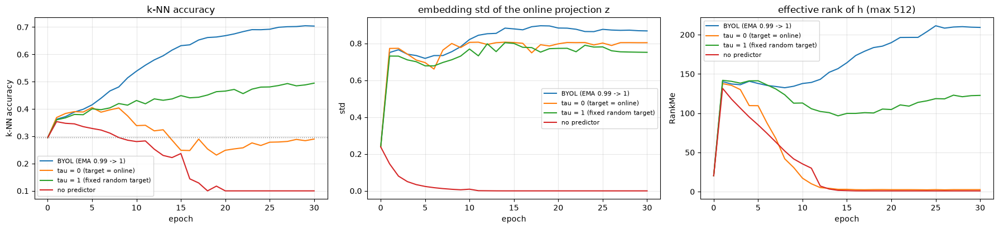

,knn_acc,linear_acc,rankme_h,rankme_z,std_z,final_loss
BYOL (EMA 0.99 -> 1),70.4%,75.4%,209,22,0.87,0.17
tau = 0 (target = online),29.0%,40.1%,3,1,0.80,0.23
tau = 1 (fixed random target),49.5%,61.7%,123,19,0.75,0.63
no predictor,10.0%,10.0%,1,1,0.00,0.00


In [26]:
byol_runs = {"abl_byol": "BYOL (EMA 0.99 -> 1)", "col_byol_ema0": "tau = 0 (target = online)",
             "col_byol_ema1": "tau = 1 (fixed random target)", "col_byol_no_predictor": "no predictor"}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
plot_runs(byol_runs, "knn_acc", axes[0], title="k-NN accuracy", ylabel="k-NN accuracy")
axes[0].axhline(RANDOM_INIT_KNN, color="gray", ls=":", lw=1)
plot_runs(byol_runs, "std_z", axes[1], title="embedding std of the online projection z", ylabel="std")
plot_runs(byol_runs, "rankme_h", axes[2], title="effective rank of h (max 512)", ylabel="RankMe")
plt.tight_layout()
plt.show()
results_table(byol_runs, columns=("knn_acc", "linear_acc", "rankme_h", "rankme_z", "std_z", "final_loss"))

### Takeaways (BYOL)

* **BYOL learns without negatives**: 70.4% k-NN / 75.4% linear after 30 epochs, with an embedding std of 0.87 and RankMe of $h$ at 209.
* **No predictor → complete collapse**: loss 0, std 0, 10.0% accuracy — exactly chance. The predictor is not optional.
* **$\tau = 1$ (fixed random target)** gives 49.5% k-NN / 61.7% linear, 20 points above the random network that produces the targets. This is the observation BYOL started from: predicting even a random target improves the representation.
* **$\tau = 0$ (target = online, i.e. SimSiam)** learns for five epochs (41% k-NN) and then collapses *dimensionally*: the RankMe of $h$ falls from 138 to 2.6 and the k-NN accuracy to 29%, while the **embedding std stays at 0.80**. At this learning rate the EMA is what keeps training stable — and std alone would not have warned us.
* Even the healthy BYOL uses only 22 of the 256 dimensions of $z$.

<a id='SimSiam'></a>
# SimSiam: stop-gradient is all you need?

Five months after BYOL, Chen & He asked how much of it can be removed. **SimSiam** is BYOL **without the momentum encoder**: one network, shared weights, a predictor on one side and a stop-gradient on the other.

$$
\mathcal{L} = \tfrac{1}{2}\, D\big(p_1, \operatorname{stopgrad}(z_2)\big) + \tfrac{1}{2}\, D\big(p_2, \operatorname{stopgrad}(z_1)\big), \qquad D(p, z) = -\cos(p, z), \quad p = q(z).
$$

No negatives, no large batch (it works from a batch of 64 to 4096), no momentum encoder, and it reaches 71.3% on ImageNet. The paper's Figure 2 is the single most instructive plot of non-contrastive learning, and we are going to reproduce it: with stop-gradient the embedding std stays at $1/\sqrt{d}$ and the accuracy grows; **without stop-gradient the std drops to zero within the first iterations** and the k-NN accuracy stays at chance.

The same paper positions the methods relative to each other, which is a helpful map:

| Starting from SimSiam | you get |
|---|---|
| add negatives (and drop the predictor and the stop-gradient) | SimCLR |
| add a momentum encoder | BYOL |
| add online clustering (and drop the predictor) | SwAV |

**The authors' hypothesis: alternating optimization.** SimSiam can be read as solving

$$
\min_{\theta, \eta}\ \mathbb{E}_{x, t}\, \big\lVert f_\theta(t(x)) - \eta_x \big\rVert^2 ,
$$

where $\eta_x$ is a per-image target vector (not a network output). Alternate two steps, as in k-means or EM: (1) fix $\theta$ and set $\eta_x$ to the average embedding of the image over augmentations; (2) fix $\eta$ and take a gradient step on $\theta$. Using the embedding of *one* other view as $\eta_x$ is a one-sample estimate of step (1), "fix $\eta$" is the stop-gradient, and the predictor compensates for using one sample instead of the expectation. It is a hypothesis, not a proof — DirectPred later gave the dynamical argument — but it explains why stop-gradient changes the problem *qualitatively*: with it, we are no longer descending a single loss in all variables.

In [27]:
def negative_cosine(p, z, stop_grad=True):
    return -F.cosine_similarity(p, z.detach() if stop_grad else z, dim=1).mean()


class SimSiam(SSLMethod):
    def __init__(self, backbone, feat_dim, proj_dim=2048, hidden_dim=2048, pred_hidden_dim=512, stop_grad=True,
                 predictor=True):
        super().__init__()
        self.backbone = backbone
        self.projector = mlp([feat_dim, hidden_dim, hidden_dim, proj_dim], last_bn=True)
        self.predictor = mlp([proj_dim, pred_hidden_dim, proj_dim]) if predictor else nn.Identity()
        self.stop_grad = stop_grad

    def forward(self, x1, x2):
        z1, z2 = self.projector(self.backbone(x1)), self.projector(self.backbone(x2))
        p1, p2 = self.predictor(z1), self.predictor(z2)
        return 0.5 * (negative_cosine(p1, z2, self.stop_grad) + negative_cosine(p2, z1, self.stop_grad))

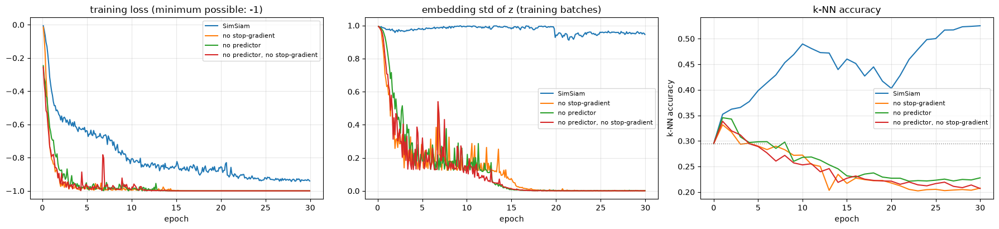

,knn_acc,linear_acc,rankme_h,rankme_z,std_z,final_loss
SimSiam,52.5%,66.2%,27,9,0.97,-0.94
no stop-gradient,20.8%,25.1%,3,1,0.00,-1.00
no predictor,22.8%,27.2%,4,1,0.00,-1.00
"no predictor, no stop-gradient",20.7%,28.6%,3,1,0.00,-1.00


In [28]:
simsiam_runs = {"abl_simsiam": "SimSiam", "col_simsiam_no_stopgrad": "no stop-gradient",
                "col_simsiam_no_predictor": "no predictor", "col_simsiam_no_both": "no predictor, no stop-gradient"}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
for name, label in simsiam_runs.items():
    s = load_steps(name)
    axes[0].plot(s.epoch, s.loss, label=label)
    axes[1].plot(s.epoch, s.std_z, label=label)
axes[0].set_title("training loss (minimum possible: -1)"); axes[1].set_title("embedding std of z (training batches)")
for ax in axes[:2]:
    ax.set_xlabel("epoch"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
plot_runs(simsiam_runs, "knn_acc", axes[2], title="k-NN accuracy", ylabel="k-NN accuracy")
axes[2].axhline(RANDOM_INIT_KNN, color="gray", ls=":", lw=1)
plt.tight_layout()
plt.show()
results_table(simsiam_runs, columns=("knn_acc", "linear_acc", "rankme_h", "rankme_z", "std_z", "final_loss"))

### Takeaways (SimSiam)

* We reproduce Figure 2 of the paper: **without stop-gradient, without the predictor, or without both, the loss goes to −1 and the embedding std to 0**. The k-NN accuracy of the three collapsed runs is 21–23%, below the random network.
* With both components SimSiam trains: 52.5% k-NN, 66.2% linear, embedding std 0.97.
* But look at the effective rank of $h$: **27 of 512**. The embedding has not collapsed to a point, yet it lives in a small subspace, and the accuracy is far below SimCLR (76.3%) and BYOL (70.4%) under the same budget. Something is wrong with this run, and the std does not show it.

## Experiment: collapse is not all-or-nothing

Stop-gradient and a predictor keep SimSiam away from *complete* collapse, but nothing in the method guarantees that the embedding uses all of its dimensions. How close it gets depends on ordinary hyperparameters. Below, five SimSiam runs that differ only in the learning rate (the value for a batch of 256; the runs above use 0.12).

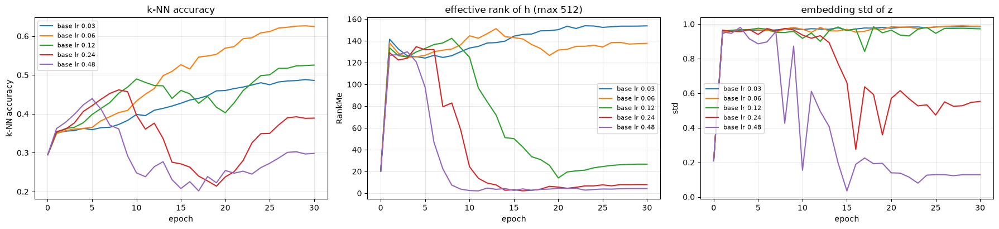

,knn_acc,linear_acc,rankme_h,rankme_z,std_z,final_loss
base lr 0.03,48.6%,58.5%,154,513,0.98,-0.72
base lr 0.06,62.5%,70.4%,138,188,0.99,-0.88
base lr 0.12,52.5%,66.2%,27,9,0.97,-0.94
base lr 0.24,38.9%,48.7%,8,2,0.55,-0.80
base lr 0.48,29.8%,37.1%,4,1,0.13,-0.75


In [29]:
lr_runs = {"lr_simsiam_0.03": 0.03, "lr_simsiam_0.06": 0.06, "abl_simsiam": 0.12, "lr_simsiam_0.24": 0.24, "lr_simsiam_0.48": 0.48}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
labels = {k: f"base lr {v}" for k, v in lr_runs.items()}
plot_runs(labels, "knn_acc", axes[0], title="k-NN accuracy", ylabel="k-NN accuracy")
plot_runs(labels, "rankme_h", axes[1], title="effective rank of h (max 512)", ylabel="RankMe")
plot_runs(labels, "std_z", axes[2], title="embedding std of z", ylabel="std")
plt.tight_layout()
plt.show()
results_table(labels, columns=("knn_acc", "linear_acc", "rankme_h", "rankme_z", "std_z", "final_loss"))

### Takeaways (learning rate and partial collapse)

* **The learning rate moves SimSiam continuously from healthy to collapsed.** RankMe of $h$: 154 → 138 → 27 → 8 → 4 for base learning rates 0.03 → 0.06 → 0.12 → 0.24 → 0.48; k-NN accuracy: 48.6% → 62.5% → 52.5% → 38.9% → 29.8%.
* The usable window is narrow: 0.03 is healthy but slow, 0.06 is the best, 0.12 is already dimensionally collapsed.
* **The embedding std is blind to it**: it is 0.97–0.99 for the first three runs, while the rank drops by a factor of 6. The std reacts only when the damage is already severe: 0.55 at 0.24 and 0.13 at 0.48.
* **The loss is misleading**: the collapsed run at 0.12 has a *lower* loss (−0.94) than the healthy one at 0.06 (−0.88).
* A practical confession: 0.12 was our choice for SimSiam after 20-epoch pilot runs, where it had the best k-NN accuracy. In the 100-epoch run of the final comparison it collapsed to rank 4 and 36.5% k-NN, and we had to repeat it with 0.06. For methods with collapse dynamics, tune with the rank on the screen, not with early accuracy.

## Do non-contrastive methods need large batches? Do they need the same augmentations?

Two claims from the BYOL and SimSiam papers that we can check directly, because we already have the contrastive counterparts:

* **Batch size.** Without negatives there is no reason for a large batch (apart from BatchNorm statistics). BYOL reports stable accuracy from a batch of 4096 down to 256, where SimCLR loses several points.
* **Augmentations.** BYOL reports a much smaller drop than SimCLR when colour distortions are removed. The intuition: SimCLR can satisfy its loss with the histogram shortcut alone (separating *different* images is easy by colour), while BYOL has to predict the target's *whole* embedding, including whatever it encodes beyond colour.

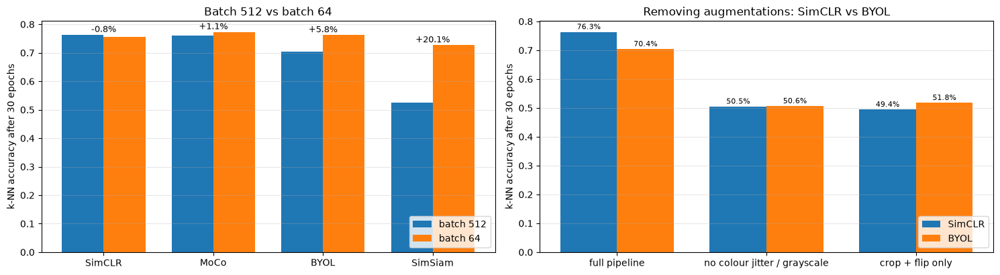

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
methods = {"simclr": "SimCLR", "moco": "MoCo", "byol": "BYOL", "simsiam": "SimSiam"}
pos, width = np.arange(len(methods)), 0.38
big = [summary.loc[f"abl_{m}", "knn_acc"] for m in methods]
small = [summary.loc[f"batch_{m}_64", "knn_acc"] for m in methods]
axes[0].bar(pos - width / 2, big, width, label="batch 512"); axes[0].bar(pos + width / 2, small, width, label="batch 64")
for i, (b, s) in enumerate(zip(big, small)):
    axes[0].text(i, max(b, s) + 0.01, f"{s - b:+.1%}", ha="center", fontsize=9)
axes[0].set_xticks(pos, methods.values()); axes[0].set_ylabel("k-NN accuracy after 30 epochs"); axes[0].set_title("Batch 512 vs batch 64")
axes[0].grid(alpha=0.3, axis="y"); axes[0].legend(loc="lower right")

settings = {"full pipeline": "abl_{}", "no colour jitter / grayscale": "aug_{}_no_color", "crop + flip only": "aug_{}_crop_only"}
pos, width = np.arange(len(settings)), 0.38
for j, (m, label) in enumerate([("simclr", "SimCLR"), ("byol", "BYOL")]):
    vals = [summary.loc[pattern.format(m), "knn_acc"] for pattern in settings.values()]
    axes[1].bar(pos + (j - 0.5) * width, vals, width, label=label)
    for i, v in enumerate(vals):
        axes[1].text(i + (j - 0.5) * width, v + 0.01, f"{v:.1%}", ha="center", fontsize=8)
axes[1].set_xticks(pos, settings.keys()); axes[1].set_ylabel("k-NN accuracy after 30 epochs"); axes[1].set_title("Removing augmentations: SimCLR vs BYOL")
axes[1].grid(alpha=0.3, axis="y"); axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

### Takeaways (batch size and augmentations without negatives)

* **Non-contrastive methods do not need large batches** — here they are *better* with a small one: from batch 512 to 64 SimCLR changes by −0.8 points and MoCo by +1.1, while BYOL gains 5.8 (70.4% → 76.2%) and SimSiam 20.2 (52.5% → 72.7%).
* Read the gains with care, two things are mixed in: a batch of 64 makes 8× more optimizer steps in 30 epochs, and SimSiam at batch 512 is the partially collapsed run from above (RankMe 27 against 204 at batch 64). The honest conclusion is "a large batch with a linearly scaled learning rate is the dangerous regime for BYOL and SimSiam", not "small batches are better".
* **Augmentations: we do not reproduce BYOL's robustness.** Without colour distortion SimCLR falls from 76.3% to 50.5% and BYOL from 70.4% to 50.6%; with crop + flip only they are at 49.4% and 51.8%. BYOL's drop is smaller (about 19 points against 26), but mostly because it starts lower after 30 epochs — both methods end at the same 50%. The colour shortcut is a property of the *views*, and no method of this lecture is immune to it.

<a id='Redundancy'></a>
# Redundancy reduction: Barlow Twins and VICReg

BYOL and SimSiam avoid collapse through their *dynamics*, which is hard to reason about. A third family prevents it **by construction**, with a symmetric architecture (no predictor, no stop-gradient, no momentum encoder) and no negatives: put the constraint directly on the **statistics of the embedding dimensions over the batch**.

## Barlow Twins

Standardize every embedding dimension over the batch and compute the **cross-correlation matrix** between the two views, $C \in \mathbb{R}^{D \times D}$, $C_{ij} = \frac{1}{N}\sum_b \tilde z^{(1)}_{b,i}\, \tilde z^{(2)}_{b,j}$. Ask it to be the identity:

$$
\mathcal{L}_{\text{BT}} = \underbrace{\sum_i (1 - C_{ii})^2}_{\text{invariance: dimension } i \text{ agrees across views}} + \lambda \underbrace{\sum_i \sum_{j \ne i} C_{ij}^2}_{\text{redundancy reduction: dimensions are decorrelated}} .
$$

A constant output is impossible (a constant dimension has no variance, so $C_{ii}$ cannot be 1), and dimensional collapse is penalized by the off-diagonal term (two dimensions that carry the same signal are correlated). The name refers to the neuroscientist Horace Barlow's *redundancy reduction* hypothesis for sensory coding.

## VICReg

VICReg makes the three requirements explicit and separate:

$$
\mathcal{L}_{\text{VICReg}} = \lambda\, \underbrace{\tfrac{1}{N}\sum_b \lVert z_b^{(1)} - z_b^{(2)} \rVert^2}_{\textbf{I}\text{nvariance}}
+ \mu\, \underbrace{\tfrac{1}{D}\sum_j \max\big(0,\, 1 - \operatorname{std}(z_{\cdot j})\big)}_{\textbf{V}\text{ariance: every dimension stays alive}}
+ \nu\, \underbrace{\tfrac{1}{D}\sum_{i \ne j} \operatorname{Cov}(Z)_{ij}^2}_{\textbf{C}\text{ovariance: dimensions are decorrelated}} ,
$$

with the variance and covariance terms applied to each branch separately ($\lambda = \mu = 25$, $\nu = 1$). The **variance** term prevents complete collapse, the **covariance** term prevents dimensional collapse. Because the regularizers act on each branch on its own, the two branches need not share weights or even architecture — convenient for multi-modal setups.

Both methods like a **wide projector** (8192 dimensions in the papers, 2048 here): decorrelating many dimensions of $z$ is what spreads information in $h$.

In [31]:
def off_diagonal(m):
    """All off-diagonal elements of a square matrix as a flat vector."""
    n = m.shape[0]
    return m.flatten()[:-1].view(n - 1, n + 1)[:, 1:].flatten()


def barlow_twins_loss(z1, z2, lambd=5e-3):
    """Make the cross-correlation matrix of the two views' embeddings equal to the identity."""
    n, d = z1.shape
    z1 = (z1 - z1.mean(0)) / z1.std(0).clamp_min(1e-6)                  # standardize every dimension over the batch
    z2 = (z2 - z2.mean(0)) / z2.std(0).clamp_min(1e-6)
    c = z1.T @ z2 / n                                                   # (D, D) cross-correlation
    on_diag = (torch.diagonal(c) - 1).pow(2).sum()                      # invariance: c_ii -> 1
    off_diag = off_diagonal(c).pow(2).sum()                             # redundancy reduction: c_ij -> 0
    return on_diag + lambd * off_diag


class BarlowTwins(SSLMethod):
    def __init__(self, backbone, feat_dim, proj_dim=2048, hidden_dim=2048, lambd=5e-3):
        super().__init__()
        self.backbone = backbone
        self.projector = mlp([feat_dim, hidden_dim, hidden_dim, proj_dim])
        self.lambd = lambd

    def forward(self, x1, x2):
        return barlow_twins_loss(self.projector(self.backbone(x1)), self.projector(self.backbone(x2)), self.lambd)


def vicreg_loss(z1, z2, sim_coeff=25.0, var_coeff=25.0, cov_coeff=1.0):
    n, d = z1.shape
    invariance = F.mse_loss(z1, z2)                                     # the two views should match
    z1, z2 = z1 - z1.mean(0), z2 - z2.mean(0)
    std1, std2 = (z1.var(0) + 1e-4).sqrt(), (z2.var(0) + 1e-4).sqrt()
    variance = 0.5 * (F.relu(1 - std1).mean() + F.relu(1 - std2).mean())    # every dimension keeps std >= 1
    cov1, cov2 = z1.T @ z1 / (n - 1), z2.T @ z2 / (n - 1)
    covariance = (off_diagonal(cov1).pow(2).sum() + off_diagonal(cov2).pow(2).sum()) / d   # decorrelate dimensions
    return sim_coeff * invariance + var_coeff * variance + cov_coeff * covariance


class VICReg(SSLMethod):
    def __init__(self, backbone, feat_dim, proj_dim=2048, hidden_dim=2048, sim_coeff=25.0, var_coeff=25.0,
                 cov_coeff=1.0):
        super().__init__()
        self.backbone = backbone
        self.projector = mlp([feat_dim, hidden_dim, hidden_dim, proj_dim])
        self.coeffs = (sim_coeff, var_coeff, cov_coeff)

    def forward(self, x1, x2):
        return vicreg_loss(self.projector(self.backbone(x1)), self.projector(self.backbone(x2)), *self.coeffs)


torch.manual_seed(0)
z = torch.randn(256, 32)
print(f"Barlow Twins | identical views, decorrelated dims: {barlow_twins_loss(z, z).item():8.3f}"
      f" | unrelated views: {barlow_twins_loss(z, torch.randn(256, 32)).item():8.3f}"
      f" | all dims equal: {barlow_twins_loss(z[:, :1].expand(-1, 32), z[:, :1].expand(-1, 32)).item():8.3f}")
print(f"VICReg       | identical views, decorrelated dims: {vicreg_loss(z, z).item():8.3f}"
      f" | unrelated views: {vicreg_loss(z, torch.randn(256, 32)).item():8.3f}"
      f" | collapsed to a constant: {vicreg_loss(torch.ones(256, 32), torch.ones(256, 32)).item():8.3f}")

Barlow Twins | identical views, decorrelated dims:    0.018 | unrelated views:   32.244 | all dims equal:    4.922
VICReg       | identical views, decorrelated dims:    0.682 | unrelated views:   50.714 | collapsed to a constant:   24.750


## Experiment: what each VICReg term does

VICReg is the ideal method for an ablation, because each term has one job. We switch the variance and covariance terms off, one at a time and both.

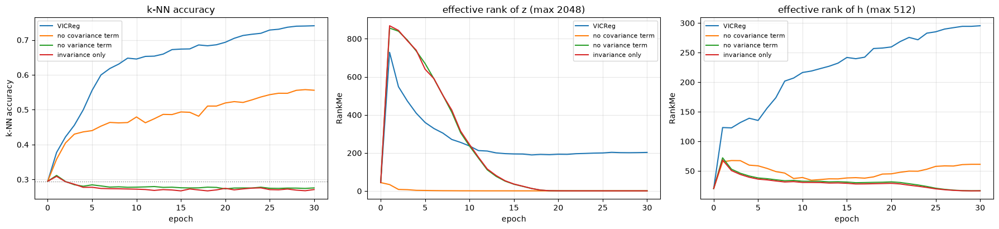

,knn_acc,linear_acc,rankme_h,rankme_z,std_z
VICReg,74.1%,78.3%,295,203,1.00
no covariance term,55.6%,66.7%,61,1,0.97
no variance term,27.6%,34.5%,16,1,0.00
invariance only,27.1%,34.9%,16,1,0.00


In [32]:
vic_runs = {"abl_vicreg": "VICReg", "col_vicreg_no_cov": "no covariance term", "col_vicreg_no_var": "no variance term",
            "col_vicreg_no_var_no_cov": "invariance only"}
fig, axes = plt.subplots(1, 3, figsize=(18, 4.2))
plot_runs(vic_runs, "knn_acc", axes[0], title="k-NN accuracy", ylabel="k-NN accuracy")
axes[0].axhline(RANDOM_INIT_KNN, color="gray", ls=":", lw=1)
plot_runs(vic_runs, "rankme_z", axes[1], title="effective rank of z (max 2048)", ylabel="RankMe")
plot_runs(vic_runs, "rankme_h", axes[2], title="effective rank of h (max 512)", ylabel="RankMe")
plt.tight_layout()
plt.show()
results_table(vic_runs, columns=("knn_acc", "linear_acc", "rankme_h", "rankme_z", "std_z"))

### Takeaways (VICReg terms)

* Full VICReg: 74.1% k-NN / 78.3% linear, RankMe 295 for $h$ and 203 for $z$.
* **No variance term → complete collapse** (std 0, 27–28% k-NN), with or without the covariance term. The covariance term alone cannot help: a constant embedding has zero covariance.
* **No covariance term → the purest dimensional collapse of the lecture.** The variance term is satisfied (std of $z$ is 0.97), but the RankMe of $z$ is **1.07 of 2048**: every dimension has unit variance, and all of them carry the same signal. k-NN on $z$ gives 28.2%.
* The backbone suffers less than the projector: $h$ keeps a rank of 61 and 55.6% k-NN. As with SimCLR's projection head, the head absorbs part of the damage.
* Each term has one job: invariance makes the views agree, variance prevents the point, covariance prevents the line.

## Contrastive and non-contrastive are two views of the same matrix

The covariance term of VICReg and the negative term of a contrastive loss look unrelated: one works on **pairs of dimensions**, the other on **pairs of samples**. Garrido et al. (2022) showed that they are algebraically close. For an embedding matrix $Z \in \mathbb{R}^{N \times D}$:

* a **sample-contrastive** criterion penalizes the off-diagonal of the **Gram matrix** $Z Z^\top \in \mathbb{R}^{N \times N}$ — similarities between *different images* (SimCLR, MoCo);
* a **dimension-contrastive** criterion penalizes the off-diagonal of the **covariance matrix** $Z^\top Z \in \mathbb{R}^{D \times D}$ — correlations between *different dimensions* (Barlow Twins, VICReg).

And the two are tied by a simple identity: $\lVert Z Z^\top \rVert_F = \lVert Z^\top Z \rVert_F$.

In [33]:
torch.manual_seed(0)
Z = F.normalize(torch.randn(512, 128), dim=1)                # rows have unit norm (as in a contrastive loss)
gram, cov = Z @ Z.T, Z.T @ Z
print(f"||Z Z^T||_F^2 = {gram.pow(2).sum().item():.4f} (512 x 512, samples) | ||Z^T Z||_F^2 = {cov.pow(2).sum().item():.4f} (128 x 128, dimensions)")
print(f"off-diagonal part of the Gram matrix: {gram.pow(2).sum().item() - gram.diagonal().pow(2).sum().item():.4f}"
      f" = sum of squared similarities between different samples")

||Z Z^T||_F^2 = 2564.6296 (512 x 512, samples) | ||Z^T Z||_F^2 = 2564.6296 (128 x 128, dimensions)
off-diagonal part of the Gram matrix: 2052.6296 = sum of squared similarities between different samples


If the rows have unit norm, the diagonal of the Gram matrix is fixed, so *pushing different samples apart* (shrinking the off-diagonal of $ZZ^\top$) is the same as *shrinking $\lVert Z^\top Z \rVert_F$*, which — with the variance of each dimension held up — means decorrelating the dimensions. Negatives and decorrelation are two ways of asking for the same thing: **an embedding that fills the space**. The paper's empirical message is equally important: the reported gaps between the families largely disappear when each method is tuned carefully (for example, SimCLR can be brought to VICReg's level, and VICReg does not really need 8192 dimensions).

<a id='Comparison'></a>
# All methods under the same budget

Time to put everything side by side. Six methods, the same ResNet-18, the same 100k unlabeled images, the same augmentations, optimizer and schedule, **100 epochs** each. Method-specific settings follow the papers, scaled down (projector widths, $\tau = 0.2$, momentum 0.99, queue of 16,384); beyond that only the learning rate was chosen per method, so differences of a point or two should not be over-interpreted. SimSiam appears twice: with the learning rate that survived (0.06) and with the one from the pilot runs (0.12), which did not.

Two reference rows: the **random-init** backbone, and the **supervised** ResNet-18 trained on the 5,000 labeled images (which the self-supervised runs use only for the k-NN / linear probe).

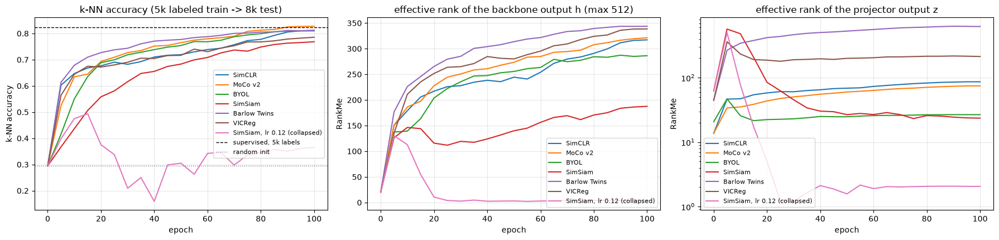

,knn_acc,linear_acc,rankme_h,rankme_z,alignment,uniformity,minutes
SimCLR,81.2%,84.0%,317,86,0.15,-3.70,32
MoCo v2,82.8%,85.9%,321,75,0.14,-3.67,41
BYOL,81.0%,84.6%,286,27,0.11,-3.13,41
SimSiam,76.9%,80.8%,188,24,0.06,-1.84,32
Barlow Twins,81.1%,84.1%,344,623,0.20,-3.88,32
VICReg,78.6%,82.3%,338,213,0.21,-3.74,32
"SimSiam, lr 0.12 (collapsed)",36.5%,44.7%,4,2,0.13,-1.29,33
"supervised, 5k labels",82.4%,82.0%,177,9,0.32,-2.30,1
random init,29.5%,–,20,–,–,–,0


In [34]:
main_runs = {"simclr": "SimCLR", "moco": "MoCo v2", "byol": "BYOL", "simsiam_lr0.06": "SimSiam", "barlow_twins": "Barlow Twins", "vicreg": "VICReg"}
collapsed_run = {"simsiam": "SimSiam, lr 0.12 (collapsed)"}
table = summary.loc[list(main_runs) + ["simsiam", "supervised_5k"], ["knn_acc", "linear_acc", "rankme_h", "rankme_z", "alignment", "uniformity", "minutes"]]
table.index = list(main_runs.values()) + list(collapsed_run.values()) + ["supervised, 5k labels"]
random_row = load_run("simclr").iloc[0]
table.loc["random init"] = [random_row.knn_acc, np.nan, random_row.rankme_h, np.nan, np.nan, np.nan, 0]

fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))
plot_runs({**main_runs, **collapsed_run}, "knn_acc", axes[0], title="k-NN accuracy (5k labeled train -> 8k test)", ylabel="k-NN accuracy")
axes[0].axhline(summary.loc["supervised_5k", "knn_acc"], color="black", ls="--", lw=1, label="supervised, 5k labels")
axes[0].axhline(RANDOM_INIT_KNN, color="gray", ls=":", lw=1, label="random init")
axes[0].legend(fontsize=8, loc="center right")
plot_runs({**main_runs, **collapsed_run}, "rankme_h", axes[1], title="effective rank of the backbone output h (max 512)", ylabel="RankMe")
plot_runs({**main_runs, **collapsed_run}, "rankme_z", axes[2], title="effective rank of the projector output z", ylabel="RankMe")
axes[2].set_yscale("log")
plt.tight_layout()
plt.show()
(table.style.format({"knn_acc": "{:.1%}", "linear_acc": "{:.1%}", "rankme_h": "{:.0f}", "rankme_z": "{:.0f}", "alignment": "{:.2f}",
                     "uniformity": "{:.2f}", "minutes": "{:.0f}"}, na_rep="–")
 .background_gradient(subset=["knn_acc", "linear_acc"], cmap="Greens"))

## Looking at the learned spaces

Numbers first, then pictures. For every method: the singular value spectrum of the backbone output $h$ and of the projector output $z$ on the test set, a t-SNE of $h$, and nearest neighbours of a few test images. (As Lecture 3 warned: t-SNE shows neighbourhoods, not geometry.)

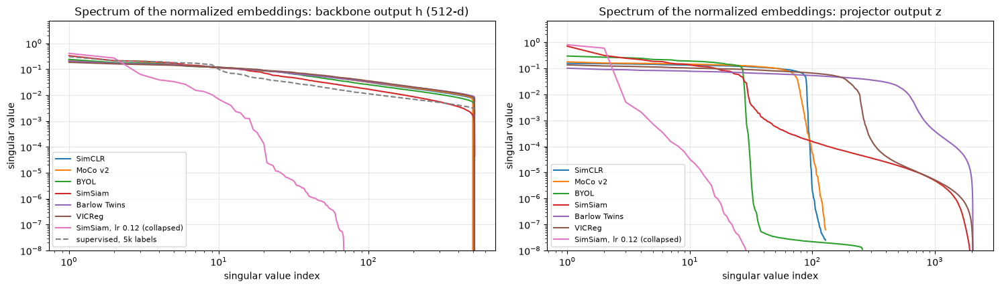

In [35]:
def load_artifact(name, kind):
    return pd.read_csv(os.path.join(RESULTS_DIR, "artifacts", f"{name}_{kind}.csv"))


fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
for name, label in {**main_runs, **collapsed_run, "supervised_5k": "supervised, 5k labels"}.items():
    spec = load_artifact(name, "spectrum")
    for ax, space in zip(axes, ["backbone h", "projector z"]):
        if name == "supervised_5k" and space == "projector z":
            continue                                            # the "projector" of the supervised model is its 10-way classifier
        d = spec[spec.space == space]
        ax.plot(d["index"], d.sigma, label=label, ls="--" if name == "supervised_5k" else "-")
for ax, title in zip(axes, ["backbone output h (512-d)", "projector output z"]):
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_ylim(bottom=1e-8)      # the collapsed run goes far below
    ax.set_xlabel("singular value index"); ax.set_ylabel("singular value"); ax.set_title(f"Spectrum of the normalized embeddings: {title}")
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

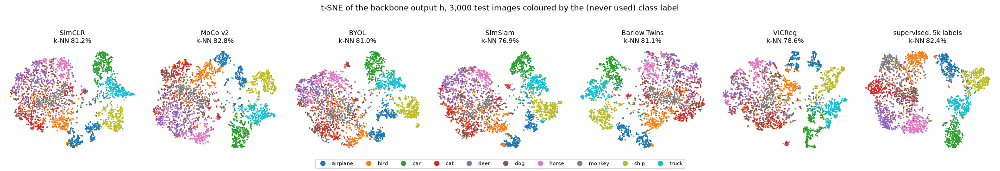

In [36]:
tsne_runs = {**main_runs, "supervised_5k": "supervised, 5k labels"}
fig, axes = plt.subplots(1, len(tsne_runs), figsize=(3.1 * len(tsne_runs), 3.5))
for ax, (name, label) in zip(axes, tsne_runs.items()):
    d = load_artifact(name, "tsne")
    sc = ax.scatter(d.x, d.y, c=d.label, cmap="tab10", s=1.5)
    ax.set_title(f"{label}\nk-NN {summary.loc[name, 'knn_acc']:.1%}", fontsize=10); ax.axis("off")
fig.legend(sc.legend_elements()[0], STL10_CLASSES, loc="lower center", ncol=10, fontsize=8, markerscale=1.2)
plt.suptitle("t-SNE of the backbone output h, 3,000 test images coloured by the (never used) class label", y=1.02)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

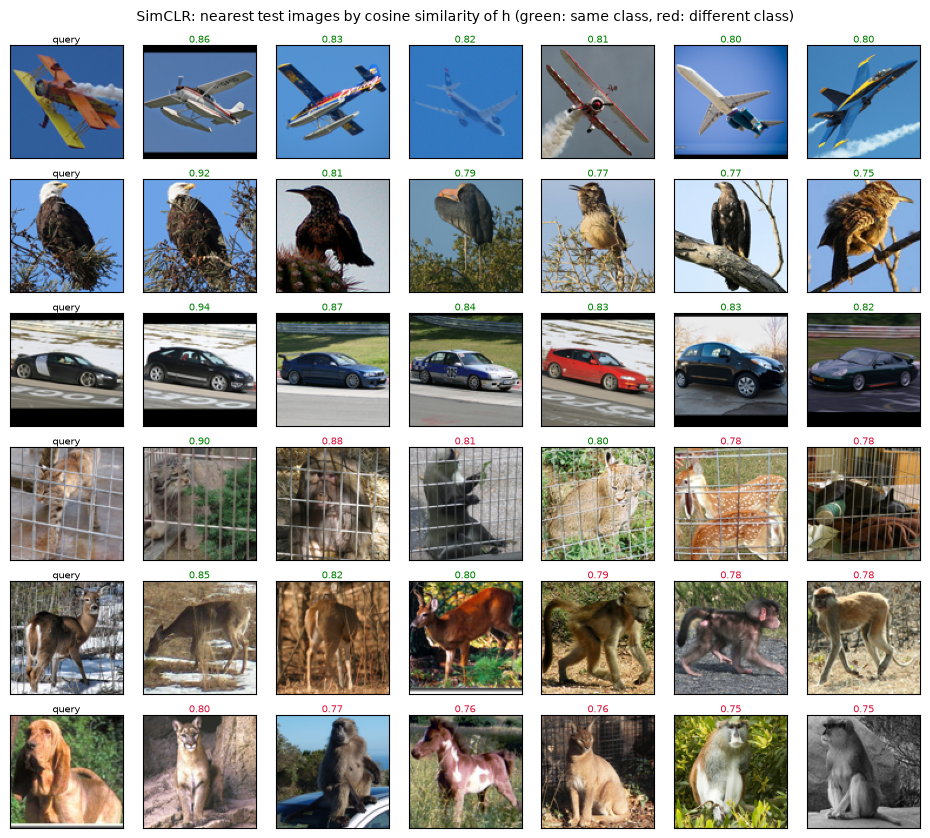

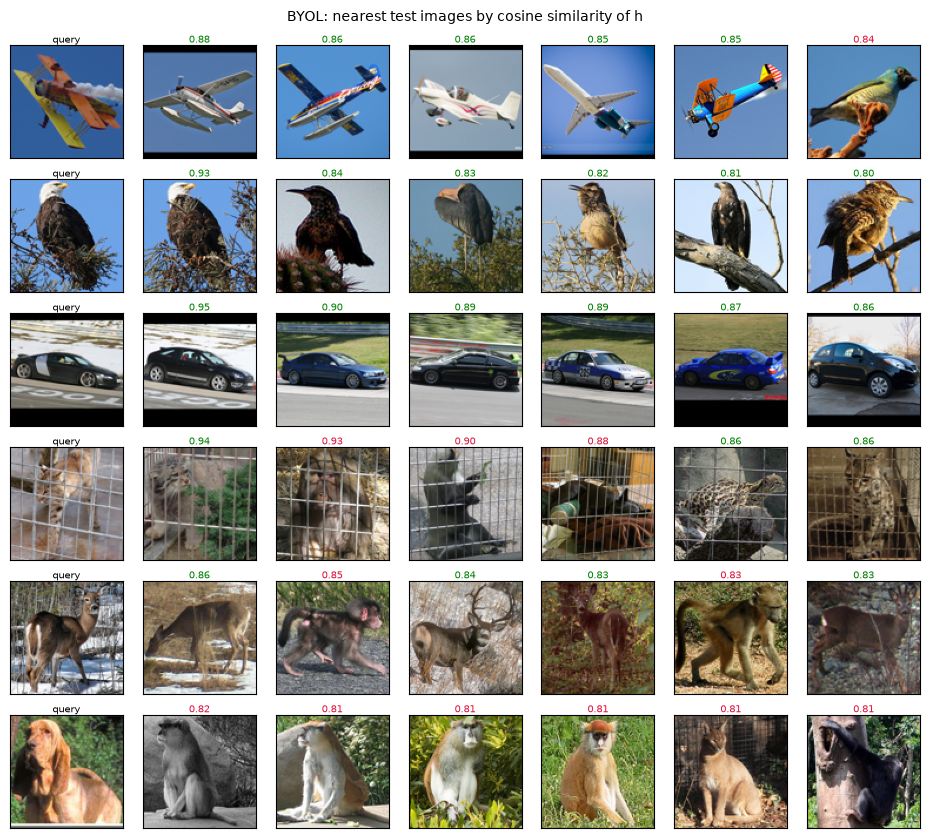

In [37]:
def show_neighbours(name, title, n_queries=6, n_neighbours=6):
    nb = load_artifact(name, "neighbours")
    queries = nb["query"].unique()[:n_queries]
    fig, axes = plt.subplots(n_queries, n_neighbours + 1, figsize=(1.35 * (n_neighbours + 1), 1.35 * n_queries + 0.4))
    for row, q in zip(axes, queries):
        row[0].imshow(test_x[q].transpose(1, 2, 0)); row[0].set_title("query", fontsize=7, pad=2)
        for ax, (_, r) in zip(row[1:], nb[nb["query"] == q].iterrows()):
            idx = int(r.neighbour)
            ax.imshow(test_x[idx].transpose(1, 2, 0))
            correct = test_y[idx] == test_y[q]
            ax.set_title(f"{r.similarity:.2f}", fontsize=7, pad=2, color="green" if correct else "crimson")
        for ax in row:
            ax.set_xticks([]); ax.set_yticks([])
    plt.suptitle(title, fontsize=10)
    plt.tight_layout()
    plt.show()


show_neighbours("simclr", "SimCLR: nearest test images by cosine similarity of h (green: same class, red: different class)")
show_neighbours("byol", "BYOL: nearest test images by cosine similarity of h")

### Takeaways (comparison of methods)

* **Five methods finish within 4 points of each other**: MoCo v2 82.8% k-NN / 85.9% linear, SimCLR 81.2% / 84.0%, Barlow Twins 81.1% / 84.1%, BYOL 81.0% / 84.6%, VICReg 78.6% / 82.3%. The family does not decide the ranking — contrastive and non-contrastive methods are mixed at the top. Everything is a single seed, so the order among the first four is not a finding.
* **SimSiam is the fragile one.** With the learning rate chosen in the pilots (0.12) it collapsed during the 100 epochs: RankMe of $h$ is 4, k-NN 36.5%. With 0.06 it trains normally and reaches 76.9% / 80.8%, still last. Removing the momentum encoder makes the method simpler to write and harder to run.
* **Against the supervised baseline** (82.4% k-NN / 82.0% linear, trained on the 5k labels with the same augmentations): four methods are 2–4 points better in linear accuracy without using a single label for the backbone; in k-NN accuracy only MoCo is ahead. On a dataset this small a well-augmented supervised network is a strong baseline — SSL wins, but not by a mile.
* **The effective rank does not rank methods.** RankMe of $h$: Barlow Twins 344, VICReg 338, MoCo 321, SimCLR 317, BYOL 286, SimSiam 188, supervised 177. VICReg has the second highest rank and the lowest accuracy of the five. RankMe is a tool for comparing runs of *one* method (and for catching collapse), as its authors say.
* The projector spaces differ far more than the backbones: Barlow Twins and VICReg spread over hundreds of dimensions (623 and 213 of 2048), the contrastive methods use 75–86 of 128, BYOL 27 of 256. The supervised network has 9: its "projector" is the 10-way classifier.
* Cost: about 32 minutes for the single-encoder methods, 41 for MoCo and BYOL with their momentum encoder.

## How much does unlabeled data help?

The promise of SSL is that unlabeled data is cheap. We train SimCLR on 10k, 30k and all 100k unlabeled images with **the same number of optimizer steps** (as in Lecture 1: when you compare data regimes, control the optimization budget — otherwise you measure "less training", not "less data").

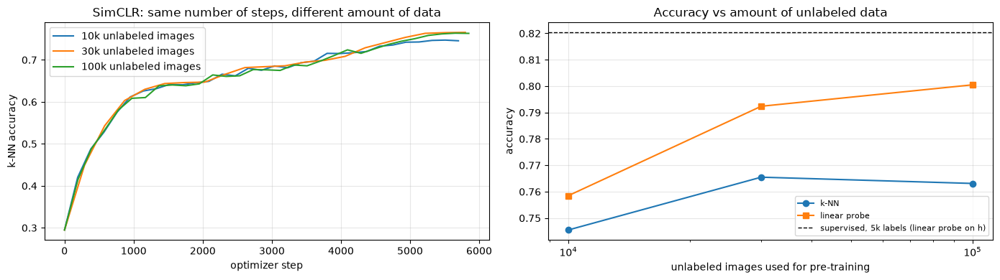

In [38]:
data_runs = {"data_simclr_10k": 10_000, "data_simclr_30k": 30_000, "abl_simclr": 100_000}
ds = summary.loc[list(data_runs)]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for name, n in data_runs.items():
    d = load_run(name).dropna(subset=["knn_acc"])
    axes[0].plot(d.step, d.knn_acc, label=f"{n // 1000}k unlabeled images")
axes[0].set_xlabel("optimizer step"); axes[0].set_ylabel("k-NN accuracy"); axes[0].set_title("SimCLR: same number of steps, different amount of data")
axes[0].grid(alpha=0.3); axes[0].legend()
axes[1].plot(list(data_runs.values()), ds.knn_acc, "o-", label="k-NN"); axes[1].plot(list(data_runs.values()), ds.linear_acc, "s-", label="linear probe")
axes[1].axhline(summary.loc["supervised_5k", "linear_acc"], color="black", ls="--", lw=1, label="supervised, 5k labels (linear probe on h)")
axes[1].set_xscale("log"); axes[1].set_xlabel("unlabeled images used for pre-training"); axes[1].set_ylabel("accuracy")
axes[1].set_title("Accuracy vs amount of unlabeled data"); axes[1].grid(alpha=0.3); axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### Takeaways (amount of data)

* With the same 5,850 optimizer steps: 10k images give 74.6% k-NN / 75.9% linear, 30k give 76.6% / 79.2%, 100k give 76.3% / 80.1%.
* **More unlabeled data helps, with quickly diminishing returns**: +3.3 points of linear accuracy from 10k to 30k, +0.9 from 30k to 100k, and k-NN accuracy is flat after 30k.
* At this step budget the amount of data is not the limit — the length of training is: the same SimCLR on the same 100k images reaches 84.0% linear after 100 epochs.
* None of the 30-epoch-budget runs beats the supervised network trained on 5k labels (82.0%). Self-supervision pays off only when both the data **and** the compute are there.

## And with a Vision Transformer? MoCo v3

Everything so far used a ResNet. This module is about ViTs, so the obvious question: do these methods work with the ViT from Lecture 1?

**MoCo v3** (Chen, Xie & He, 2021) is the paper that asked it systematically. Its findings:

* The contrastive frameworks carry over, but **training is unstable**: the k-NN curve shows sudden dips, more so with larger batches and learning rates, and the final accuracy is silently a few points lower rather than obviously broken.
* The instability starts in the **first layer**: gradient spikes appear in the patch projection first. The fix is a trick: **freeze the patch projection at its random initialization**. A random linear projection of $16 \times 16$ patches loses nothing, and the instability largely disappears. The trick helps SimCLR, BYOL and SwAV with ViTs as well.
* The method itself is the simplified MoCo we implemented: no queue (batch of 4096), symmetrized InfoNCE, a predictor, momentum encoder; AdamW with a long warmup. ViT-B reaches 76.7% linear accuracy on ImageNet.

We run the same recipe at our scale: **ViT-Ti with $8 \times 8$ patches** (144 tokens, 5.4M parameters — half the size of ResNet-18), fixed sin-cos positional embeddings, frozen patch projection, AdamW. To separate *method* from *architecture*, the same MoCo v3 objective is also trained with ResNet-18.

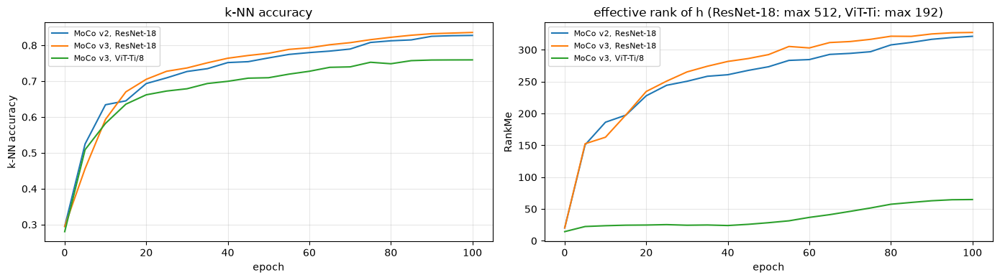

,backbone,backbone_params_m,knn_acc,linear_acc,rankme_h,minutes
name,,,,,,
"MoCo v2, ResNet-18",resnet18,11.17,0.827625,0.858750,321.239686,41.4
"MoCo v3, ResNet-18",resnet18,11.17,0.835875,0.859250,327.302518,41.5
"MoCo v3, ViT-Ti/8",vit_tiny,5.38,0.759375,0.808125,64.876184,38.6


In [39]:
vit_runs = {"moco": "MoCo v2, ResNet-18", "mocov3_resnet18": "MoCo v3, ResNet-18", "mocov3_vit_tiny": "MoCo v3, ViT-Ti/8"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_runs(vit_runs, "knn_acc", axes[0], title="k-NN accuracy", ylabel="k-NN accuracy")
plot_runs(vit_runs, "rankme_h", axes[1], title="effective rank of h (ResNet-18: max 512, ViT-Ti: max 192)", ylabel="RankMe")
plt.tight_layout()
plt.show()
summary.loc[list(vit_runs), ["backbone", "backbone_params_m", "knn_acc", "linear_acc", "rankme_h", "minutes"]].rename(index=vit_runs)

### Takeaways (ViT)

* **On ResNet-18 the queue is not needed**: MoCo v3 reaches 83.6% k-NN / 85.9% linear against 82.8% / 85.9% for MoCo v2 — the best k-NN accuracy of the lecture, with negatives from the batch only.
* **ViT-Ti/8 is clearly behind with the same objective**: 75.9% k-NN / 80.8% linear, 8 and 5 points below ResNet-18, at a similar training time (39 vs 41 minutes) and half the parameters. This is the lesson of Lecture 1 again: without the convolutional prior a ViT needs more data or more epochs, and 100k images × 100 epochs is little.
* The training curve of the ViT is smooth, without the dips described in the paper. We trained with the frozen patch projection only and did not run the unfrozen control, so we cannot attribute the stability to the trick.
* The effective rank of the ViT features is 65 of 192.

<a id='Recent'></a>
# What happened next (2022–2025)

The methods of this lecture are from 2019–2021. What survived, and where did the field go?

**1. The families merged.** The duality result above was one of several (see also Balestriero & LeCun, 2022, who relate SimCLR, VICReg and Barlow Twins to classical spectral embedding methods). The practical consensus, collected in the *Cookbook of Self-Supervised Learning* (2023): the choice between contrastive and non-contrastive matters less than the **augmentations, the projector, the training length and the tuning**.

**2. Self-distillation with ViTs won the "pure vision" track.** BYOL's recipe — a student, an EMA teacher, no negatives — plus ViTs, multi-crop and a clustering-style head became **DINO** (2021), then **iBOT** and **DINOv2** (2023) with an added masked-patch objective, then **DINOv3** (2025). These are the frozen backbones that topped our tables in Lecture 3. **Lecture 5** is about them.

**3. The contrastive loss won the image–text track.** InfoNCE between an image and its caption is **CLIP** (2021); the queue and the momentum encoder turned out to be unnecessary at batch sizes of 32k. **SigLIP** (2023) replaces the softmax over the batch by an independent sigmoid per pair, which removes the need for a global normalization over the batch. **Lecture 6** is about them.

**4. Collapse prevention is being made explicit and simple.** A clear trend of 2023–2025 is to replace the *tricks* (stop-gradient, EMA schedules, predictors, centering) by a **regularizer on the distribution of the embeddings**:
   * **EMP-SSL** (2023): a coding-rate regularizer and many (up to 200) crops per image; reaches 85% on CIFAR-10 in a single epoch.
   * **SimDINO** (2025): DINO and DINOv2 with a coding-rate term instead of their collapse-avoidance machinery; simpler and more robust to hyperparameters.
   * **LeJEPA** (2025): argues that the optimal embedding distribution is an **isotropic Gaussian** and enforces it with one regularizer (SIGReg) — no stop-gradient, no teacher, no schedules, one trade-off hyperparameter. Compare with VICReg: the same idea (constrain the statistics of $z$), with a stronger target (the whole distribution rather than its first two moments).
   * **Label-free model selection**: RankMe (Lecture 3) and **LiDAR** (2023), which measures the rank of an LDA matrix built from the SSL task itself, are used to choose hyperparameters without labels.

**5. How much of the machinery is needed depends on the scale.**
   * *Occam's Razor for SSL* (2024): for pre-training sets of up to a few hundred thousand images — our regime — the extra designs of SSL (projector, positive views, teacher–student) are reported **not** to improve the representation over a much simpler objective.
   * *You Don't Need Domain-Specific Data Augmentations…* (2024): at the scale of DINOv2, **cropping alone** (no colour jitter, no blur) is enough for state-of-the-art results. The histogram shortcut we measured is a small-data problem: with enough images, memorising colour statistics stops being the cheapest solution.
   * **I-JEPA** (2023) goes further and removes hand-crafted views altogether: predict the *embeddings* of masked image regions from the visible ones.

**6. Pure visual SSL scales.** *Scaling Language-Free Visual Representation Learning* (2025) trains DINOv2-style models and CLIP on the **same** billions of web images: the SSL models keep improving with data and model size (up to 7B parameters) and reach CLIP-level results even on visual question answering, which was considered the home turf of language supervision.

What does **not** age: the questions of this lecture. Any new method still has to say *what its views are*, *what it is invariant to*, and *what stops it from collapsing*.

<a id='Practice'></a>
# Practical guide

## Do you need to pre-train at all?

Usually not. A frozen or fine-tuned **DINOv2/v3 or SigLIP backbone** is the right starting point for natural images (Lecture 3 shows how to choose). Self-supervised pre-training on your own data is worth considering when

* the **domain is far** from web images (medical, microscopy, satellite, industrial, depth, spectrograms) **and** you have at least tens of thousands of unlabeled images;
* you need a **small or unusual architecture** for which no pretrained weights exist;
* even then, **continue from a pretrained checkpoint** rather than from random weights whenever the architecture allows it.

## Choosing and configuring a method

| Decision | Recommendation |
|---|---|
| **Method** | With one GPU and a CNN: MoCo v2, BYOL or VICReg (no large batch needed). With ViTs: DINO-style self-distillation (Lecture 5) or MoCo v3. Start from a maintained implementation ([solo-learn](https://github.com/vturrisi/solo-learn), [lightly](https://github.com/lightly-ai/lightly)). |
| **Augmentations** | Start from crop + colour jitter + grayscale + blur and **adapt them to the domain**: ask of each one whether the downstream task needs the information it removes. Colour jitter is harmful if colour is the label (flowers, histology stains); flips are harmful if orientation matters (text, chest X-rays); the crop scale must leave the object visible. |
| **Projector** | Always use one; 2–3 layers with BatchNorm; evaluate the backbone output. Wider is better for Barlow Twins / VICReg. |
| **Temperature** | 0.1–0.2 is a safe range for contrastive losses; raise it when there are few classes (many false negatives). |
| **Batch size** | Contrastive without a queue wants the largest batch you can afford; everything else is fine with 256. Scale the learning rate linearly with the batch. |
| **Training length** | SSL converges slowly: hundreds of epochs are normal, and the ranking of methods can change between 100 and 800 epochs. |
| **Multi-GPU** | Synchronize BatchNorm; gather embeddings from all devices before a contrastive or covariance loss. |

## Monitoring a run without labels

The loss value tells you little: a collapsed BYOL has a *perfect* loss, and InfoNCE values depend on the number of negatives. Watch instead:

1. **Embedding std** of the normalized projector output — must stay around 1 (in units of $1/\sqrt{D}$). A drop to 0 within the first hundreds of steps is complete collapse.
2. **Effective rank (RankMe)** of the backbone output on a fixed held-out set — a slow decline signals dimensional collapse.
3. **k-NN accuracy** on any small labeled set, if you have one — the cheapest downstream signal.
4. Nearest neighbours of a few images, by eye.

## If the run collapses or stalls

| Symptom | Things to check |
|---|---|
| std → 0 immediately (BYOL / SimSiam) | stop-gradient is really applied (`detach`); the predictor exists and has a hidden layer; BatchNorm in the projector; the target network is updated *after* the optimizer step |
| std fine, accuracy at random-init level | augmentations too weak (shortcut) or too strong (nothing shared); learning rate; the backbone output, not the projector output, is being evaluated |
| contrastive loss stuck at $\log(\text{number of candidates})$ | embeddings not normalized; temperature far too high; positives misaligned in the batch (check the target indices) |
| contrastive loss drops to ~0 very fast | a shortcut: identical views, BatchNorm leakage across the pair on multiple GPUs, duplicates in the batch |
| accuracy rises, then slowly falls | dimensional collapse (check RankMe); learning rate too high late in training; for EMA methods, momentum too low |

<a id='Summary'></a>
# Summary

* **Joint-embedding SSL** trains a network to give similar embeddings to two augmented views of an image. The **augmentations are the supervision**: the network becomes invariant to what they change, and it will exploit any shortcut they leave open (colour histograms for crop-only views).
* The trivial solution is **collapse** — the same embedding for everything (complete) or a low-dimensional subspace (dimensional). Methods differ in how they prevent it; detect it with the **embedding std** and the **effective rank**, not with the loss.
* **Contrastive methods** (SimCLR, MoCo) add negatives. InfoNCE is a $(K+1)$-way classification with a temperature; it pulls positives together (**alignment**) and spreads all embeddings over the sphere (**uniformity**), with an implicit emphasis on hard negatives controlled by $\tau$. SimCLR takes negatives from a large batch, MoCo from a **queue** filled by a **momentum encoder**.
* The **projection head** is trained and thrown away: the representation before it is better than the one the loss is applied to.
* **Non-contrastive methods** need no negatives. **BYOL** and **SimSiam** rely on an asymmetry — a **predictor** and a **stop-gradient**, plus an EMA target in BYOL; removing either of the first two leads to collapse. **Barlow Twins** and **VICReg** use a symmetric network and constrain the **variance and covariance** of the embedding dimensions.
* The two families are closer than they look: penalizing similarities between **samples** and correlations between **dimensions** are two views of the same matrix, and with equal tuning effort their accuracies are similar.
* Positives and negatives are both imperfect: **false negatives** grow as classes get fewer, the positive–negative coupling hurts small batches (DCL), and richer positives (multi-crop, nearest neighbours) help.
* These ideas are the basis of what came next: **self-distillation** (DINO family, Lecture 5) and **image–text contrastive learning** (CLIP, SigLIP, Lecture 6).

# Self-check questions

**Theory**
1. What is representation collapse? Distinguish complete and dimensional collapse and name a label-free diagnostic for each.
2. Write the InfoNCE loss for one anchor. Why is it a classification loss, and what is the role of each of: the positive, the negatives, the normalization of the embeddings, the temperature?
3. Derive the gradient of InfoNCE with respect to the similarity of a negative. Why does this amount to hard-negative mining, and how does the temperature change it?
4. Explain alignment and uniformity. What solution minimizes each of them alone?
5. Why does SimCLR need a large batch, and how does MoCo avoid it? Why must the key encoder change slowly?
6. Why does the projection head improve the representation that is taken *before* it?
7. What is a false negative? Why is the problem worse on a 10-class dataset than on ImageNet? Name two ways to reduce it.
8. List the three asymmetries between BYOL's online and target branches. Which are necessary to avoid collapse and which improve stability? How do we know that BatchNorm is not the mechanism?
9. State SimSiam's loss and the alternating-optimization interpretation of the stop-gradient.
10. Write the three terms of VICReg. Which failure does each term prevent? How is the Barlow Twins loss related to them?
11. In what sense are sample-contrastive and dimension-contrastive criteria "dual"?
12. Why is "random crop + colour distortion" much better than either alone? Why might this matter less at very large data scale?

**Practice**
1. Implement NT-Xent for a batch of $N$ pairs with one matrix product and one call of `cross_entropy`. What is its value for random embeddings? What changes for DCL?
2. Implement MoCo's queue as a ring buffer of fixed size when the batch size does not divide the queue size.
3. You train BYOL and the loss falls to almost 0 in 200 steps. Which three quantities do you look at, and what are the first four things you check in the code?
4. Your contrastive run has a healthy embedding std and RankMe, but k-NN accuracy equals that of a random network. Give three hypotheses and an experiment for each.
5. You have 300k unlabeled histopathology patches and 2k labeled ones. Design the augmentation pipeline: which of the standard augmentations do you keep, change or remove, and what would you add?
6. For a batch of 256 on one GPU, compare SimCLR, MoCo v2, BYOL and VICReg by memory, number of forward and backward passes per step, and the hyperparameters you would have to tune.
7. Compute the embedding std and RankMe of $Z = \mathbf{1} v^\top + \varepsilon E$ (all rows equal to $v$ plus small noise). Which of the two reacts to the noise scale $\varepsilon$, and why?